<div style="background:linear-gradient(120deg,#102940,#164c57);padding:30px;border-radius:18px;color:white;line-height:1.6">
  <div style="font-size:13px;letter-spacing:2px;color:#a8e7d5">PROYECTO ACADÉMICO · CIENCIA DE DATOS</div>
  <h1 style="color:white;margin:8px 0;font-size:31px">Energías renovables en Argentina</h1>
  <p style="font-size:17px;color:#e3f2f0;margin:0">Análisis exploratorio, series temporales y comparación de modelos de regresión</p>
  <div style="margin-top:22px;padding-top:12px;border-top:1px solid #57858a;color:#b9e2d9">Python · Pandas · NumPy · Matplotlib · Scikit-learn    
  </div>
</div>


**Objetivos específicos:**
- Verificar nulos, duplicados, categorías y cobertura temporal antes de agregar datos.
- Comparar la evolución anual, las fuentes energéticas y la distribución geográfica.
- Crear rezagos mensuales sobre la serie **agregada por mes**, nunca sobre filas consecutivas de centrales distintas.
- Comparar **persistencia**, **persistencia estacional**, **regresión lineal**, **Ridge**, **Lasso**, **CART** y **Random Forest** con el **mismo protocolo de evaluación**


## 1. Preparación
Se importan las librerías y se define un formato común para todos los gráficos (tamaño chico, cuadrícula suave) y para los números (miles con punto, decimales con coma).

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# Estilo de gráficos: tamaño moderado para que no se desborden
plt.rcParams.update({
    "figure.figsize": (8, 3.8), "figure.dpi": 100, "figure.autolayout": True,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "legend.fontsize": 9, "legend.frameon": False,
})

# Formato argentino de números (1.234,56)
def miles(x, dec=0):
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

pd.set_option("display.float_format", lambda x: miles(x, 2))
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

def ejes_miles(ax, eje="y"):
    eje_obj = ax.yaxis if eje == "y" else ax.xaxis
    eje_obj.set_major_formatter(FuncFormatter(lambda v, _: miles(v)))

# Constantes del proyecto
COL = "ENERGÍA GENERADA [GWh]"
FUENTES_ACTIVAS = ["EOLICO", "SOLAR", "HIDRO <=50MW", "BIOMASA", "BIOGAS"]
NOMBRE = {"EOLICO": "Eólica", "SOLAR": "Solar", "HIDRO <=50MW": "Hidro ≤50 MW",
          "BIOMASA": "Biomasa", "BIOGAS": "Biogás", "BIODIESEL": "Biodiésel"}
MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
COLOR = {"EOLICO": "#2A9D8F", "SOLAR": "#E9A23B", "HIDRO <=50MW": "#457B9D",
         "BIOMASA": "#8D6E63", "BIOGAS": "#9B5DE5", "BIODIESEL": "#9E9E9E"}

## 2. Carga y calidad de datos


In [2]:
nombres_posibles = ["Energía Renovables - Base de Datos.xlsm", "Energía_Renovables_-_Base_de_Datos.xlsm"]
ruta = next((Path(n) for n in nombres_posibles if Path(n).exists()), None)
if ruta is None:
    raise FileNotFoundError("Copiá el Excel en la misma carpeta que este notebook.")

df_original = pd.read_excel(ruta, sheet_name="Base de Datos")
print("Filas y columnas:", df_original.shape)
display(df_original.head(3))

Filas y columnas: (23057, 11)


,AÑO,CENTRAL,CENTRAL DESCRIPCIÓN,MAQUINA,FUENTE DE ENERGÍA,REGIÓN,PROVINCIA,MES,ENERGÍA GENERADA [GWh],Nueva Generación,Unnamed: 10
0,2011,AESP,AES PARANA,AESPCC01,BIODIESEL,BUENOS AIRES,BUENOS AIRES,2011-01-01,"0,00",Resto,NaN
1,2011,AESP,AES PARANA,AESPCC02,BIODIESEL,BUENOS AIRES,BUENOS AIRES,2011-01-01,"0,00",Resto,NaN
2,2011,AMEGHI,F. AMEGHINO,AMEGHI,HIDRO <=50MW,PATAGONIA,CHUBUT,2011-01-01,"13,75",Resto,NaN


### 2.1 Auditoría: qué problemas tienen los datos originales

In [3]:
auditoria = pd.DataFrame({"Tipo": df_original.dtypes.astype(str), "Nulos": df_original.isna().sum()})
display(auditoria)

col_aux = [c for c in df_original.columns if str(c).startswith("Unnamed")]
print("Columna auxiliar:", col_aux, "-> valores no vacíos:", int(df_original[col_aux].notna().sum().sum()))
print("Filas exactamente duplicadas:", df_original.duplicated().sum())

print("\nCategorías de FUENTE DE ENERGÍA (con repr para ver espacios ocultos):")
print(df_original["FUENTE DE ENERGÍA"].map(repr).value_counts().to_string())

,Tipo,Nulos
AÑO,int64,0
CENTRAL,str,0
CENTRAL DESCRIPCIÓN,object,0
MAQUINA,str,0
FUENTE DE ENERGÍA,str,0
REGIÓN,str,0
PROVINCIA,str,0
MES,datetime64[us],0
ENERGÍA GENERADA [GWh],float64,0
Nueva Generación,str,0


Columna auxiliar: ['Unnamed: 10'] -> valores no vacíos: 110
Filas exactamente duplicadas: 1

Categorías de FUENTE DE ENERGÍA (con repr para ver espacios ocultos):
FUENTE DE ENERGÍA
'HIDRO <=50MW'    7241
'EOLICO'          5954
'SOLAR'           4941
'BIOGAS'          2667
'BIOMASA'         1831
'BIODIESEL'        235
' Demanda MEM'     188


**Problemas encontrados**
- Una columna auxiliar (`Unnamed`) casi vacía: se elimina.
- Filas duplicadas: se eliminan.
- La categoría **Demanda MEM** viene con un espacio adelante (`' Demanda MEM'`). Si no se limpian los espacios, el filtro no la detecta. Además es demanda, no generación, así que se excluye.

In [4]:
df = df_original.drop(columns=col_aux).drop_duplicates().copy()
df["FUENTE DE ENERGÍA"] = df["FUENTE DE ENERGÍA"].str.strip()
df["MES"] = pd.to_datetime(df["MES"], errors="coerce")

filas_antes = len(df)
df = df[df["FUENTE DE ENERGÍA"] != "Demanda MEM"].copy()

print(f"Filas originales: {len(df_original)} | sin duplicados: {filas_antes} | sin Demanda MEM: {len(df)}")
print("\nChequeos finales:")
print("  Nulos en columnas clave :", int(df[["AÑO", "MES", "PROVINCIA", "FUENTE DE ENERGÍA", COL]].isna().sum().sum()))
print("  Fechas inválidas        :", int(df["MES"].isna().sum()))
print("  Generación negativa     :", int((df[COL] < 0).sum()))
print("  Período                 :", df["MES"].min().strftime("%Y-%m"), "a", df["MES"].max().strftime("%Y-%m"))

Filas originales: 23057 | sin duplicados: 23056 | sin Demanda MEM: 22868

Chequeos finales:
  Nulos en columnas clave : 0
  Fechas inválidas        : 0
  Generación negativa     : 0
  Período                 : 2011-01 a 2026-08


In [5]:
#ANALISIS QUE FUENTES DE ENERGIA QUE GENERAR MAS ELECTRICIDAD EN ARGENTINA

# CANTIDAD REAL DE ENERGIA GENERADA,MEDIDA EN GWh (Gigavatios hora)


energia_espanol = df["ENERGÍA GENERADA [GWh]"].describe().rename(
    index={
        'count': 'Cantidad de meses/registros',
        'mean': 'Promedio (Media)',
        'std': 'Desviación estándar',
        'min': 'Generación mínima',
        '25%': 'Primer Cuartil (25%)',
        '50%': 'Mediana (50% de los datos)',
        '75%': 'Tercer Cuartil (75%)',
        'max': 'Generación máxima'
    }
).to_frame() # <-- Esto lo transforma en una tabla



# Mostrar el resultado
energia_espanol



,ENERGÍA GENERADA [GWh]
Cantidad de meses/registros,"22.868,00"
Promedio (Media),"7,24"
Desviación estándar,"11,60"
Generación mínima,"0,00"
Primer Cuartil (25%),"0,50"
Mediana (50% de los datos),"2,35"
Tercer Cuartil (75%),"8,68"
Generación máxima,"167,82"


Demanda MEM no es una fuente de generación renovable, sino una medida de demanda eléctrica. debe ser eleminado

In [6]:
# Crear una copia para conservar los datos originales
df_original = df.copy()

# Quitar espacios adicionales
df_original["FUENTE DE ENERGÍA"] = (
    df_original["FUENTE DE ENERGÍA"].str.strip()
)

# Eliminar registros de Demanda MEM
df_original = df_original[
    df_original["FUENTE DE ENERGÍA"] != "Demanda MEM"
].copy()

# Verificar resultados
print("Filas originales:", len(df))
print("Filas después de limpieza:", len(df_original))
print("Registros Demanda MEM:",
      (df_original["FUENTE DE ENERGÍA"] == "Demanda MEM").sum())

Filas originales: 22868
Filas después de limpieza: 22868
Registros Demanda MEM: 0


In [7]:
print(df_original["FUENTE DE ENERGÍA"].value_counts())

FUENTE DE ENERGÍA
HIDRO <=50MW    7241
EOLICO          5953
SOLAR           4941
BIOGAS          2667
BIOMASA         1831
BIODIESEL        235
Name: count, dtype: int64


In [8]:
generacion_fuente = (
    df_original
    .groupby("FUENTE DE ENERGÍA")["ENERGÍA GENERADA [GWh]"]
    .sum()
    .sort_values(ascending=False)
)

print(generacion_fuente)

FUENTE DE ENERGÍA
EOLICO         107.208,65
SOLAR           23.569,79
HIDRO <=50MW    21.850,25
BIOMASA          6.810,48
BIOGAS           3.766,34
BIODIESEL        2.380,61
Name: ENERGÍA GENERADA [GWh], dtype: float64


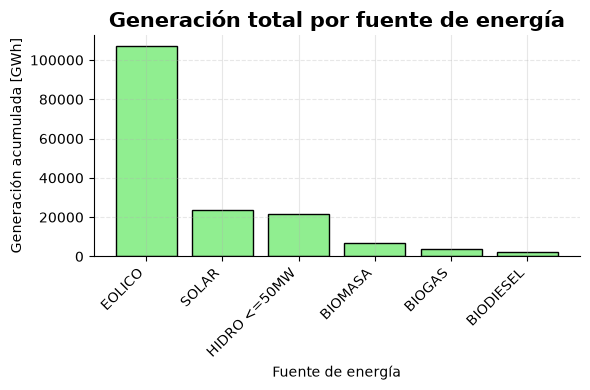

In [9]:
#GRAFICO DE BARRAS DE LA GENERACION POR FUENTE DE ENERGIA


plt.figure(figsize=(6, 4))

plt.bar(
    generacion_fuente.index,
    generacion_fuente.values,
    color="lightgreen",
    edgecolor="black"
)

plt.title(
    "Generación total por fuente de energía",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Fuente de energía")
plt.ylabel("Generación acumulada [GWh]")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show();

### Análisis de generación acumulada por fuente energética

Luego de realizar la limpieza de datos y excluir los registros correspondientes a la demanda eléctrica MEM, se analizó la generación acumulada según la fuente de energía.

Los resultados muestran que la **energía eólica representa la mayor contribución a la generación renovable** durante el período analizado.

En segundo y tercer lugar se encuentran la energía solar y la hidráulica de pequeña escala (≤50 MW), mientras que biomasa, biogás y biodiésel registran participaciones menores.

Este análisis permite identificar cuáles fueron las principales fuentes de generación renovable en el conjunto de datos y constituye un punto de partida para estudiar su evolución temporal.

**Observación:** los valores corresponden a generación acumulada, por lo que no permiten determinar directamente qué fuente tuvo el mayor crecimiento anual.

In [10]:
cobertura = (df.groupby("FUENTE DE ENERGÍA")
               .agg(Registros=(COL, "size"), Primer_mes=("MES", "min"), Ultimo_mes=("MES", "max"), Total_GWh=(COL, "sum"))
               .sort_values("Total_GWh", ascending=False))
cobertura["Primer_mes"] = cobertura["Primer_mes"].dt.strftime("%Y-%m")
cobertura["Ultimo_mes"] = cobertura["Ultimo_mes"].dt.strftime("%Y-%m")
display(cobertura)

meses_por_anio = df.groupby("AÑO")["MES"].nunique()
print("Años con menos de 12 meses:", meses_por_anio[meses_por_anio < 12].to_dict())

,Registros,Primer_mes,Ultimo_mes,Total_GWh
FUENTE DE ENERGÍA,,,,
EOLICO,5953,2011-01,2026-08,"107.208,65"
SOLAR,4941,2011-01,2026-08,"23.569,79"
HIDRO <=50MW,7241,2011-01,2026-08,"21.850,25"
BIOMASA,1831,2011-01,2026-08,"6.810,48"
BIOGAS,2667,2012-05,2026-08,"3.766,34"
BIODIESEL,235,2011-01,2012-12,"2.380,61"


Años con menos de 12 meses: {2026: 8}


**Decisiones**
- El **biodiésel** solo tiene datos de 2011 a 2012 (después no hay registros, no es que haya generado cero). Se muestra en el análisis histórico, pero no se usa para comparar crecimiento ni para proyectar.
- **2026 llega solo hasta agosto**: no se compara como año completo. Los gráficos anuales usan 2011–2025.

## 3. Análisis exploratorio (EDA)

In [11]:
#Preparación para el análisis temporal.
#Inspeccionar las columnas relacionadas con fechas
# Inspección de las variables temporales
df_original[["AÑO", "MES"]].head(10)


,AÑO,MES
0,2011,2011-01-01
1,2011,2011-01-01
2,2011,2011-01-01
3,2011,2011-01-01
4,2011,2011-01-01
5,2011,2011-01-01
6,2011,2011-01-01
7,2011,2011-01-01
8,2011,2011-01-01
9,2011,2011-01-01


In [12]:
# Cantidad de registros por año

conteo_anual = (
    df_original["AÑO"]
    .value_counts()
    .sort_index()
    .to_frame(name="Cantidad de registros")
)

conteo_anual


,Cantidad de registros
AÑO,
2011,514
2012,692
2013,606
2014,643
2015,660
2016,660
2017,699
2018,833
2019,1281


In [13]:
# Agrupamos la generación por año y fuente de energía

generacion_anual = (
    df_original
    .groupby(["AÑO", "FUENTE DE ENERGÍA"])["ENERGÍA GENERADA [GWh]"]
    .sum()
    .reset_index()
    .sort_values(["AÑO", "FUENTE DE ENERGÍA"])
)

generacion_anual

,AÑO,FUENTE DE ENERGÍA,ENERGÍA GENERADA [GWh]
0,2011,BIODIESEL,"32,49"
1,2011,BIOMASA,"97,63"
2,2011,EOLICO,"15,98"
3,2011,HIDRO <=50MW,"1.255,44"
4,2011,SOLAR,"1,76"
...,...,...,...
76,2026,BIOGAS,"343,42"
77,2026,BIOMASA,"708,49"
78,2026,EOLICO,"11.838,30"
79,2026,HIDRO <=50MW,"814,44"


In [14]:

# Generación total de energía renovable por año

generacion_total_anual = (
    df_original
    .groupby("AÑO", as_index=False)["ENERGÍA GENERADA [GWh]"]
    .sum()
    .sort_values("AÑO")
)

generacion_total_anual


,AÑO,ENERGÍA GENERADA [GWh]
0,2011,"1.403,31"
1,2012,"4.321,86"
2,2013,"1.978,47"
3,2014,"2.301,19"
4,2015,"2.510,01"
5,2016,"2.631,84"
6,2017,"2.634,75"
7,2018,"3.350,69"
8,2019,"7.812,33"
9,2020,"12.736,95"


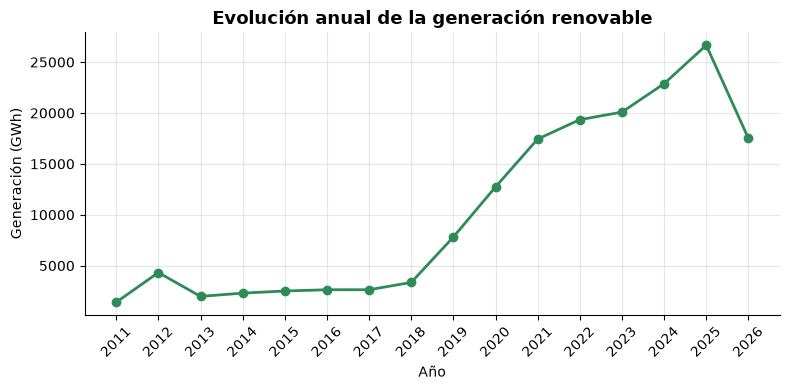

In [15]:
# Evolución anual de la generación de energías renovables

plt.figure(figsize=(8, 4))

plt.plot(
    generacion_total_anual["AÑO"],
    generacion_total_anual["ENERGÍA GENERADA [GWh]"],
    marker="o",
    color="seagreen",
    linewidth=2
)

plt.title(
    "Evolución anual de la generación renovable",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Año")
plt.ylabel("Generación (GWh)")

plt.xticks(
    generacion_total_anual["AÑO"],
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show();


### Evolución anual de la generación de energías renovables

Se representa gráficamente la generación total anual de energías renovables en Argentina, expresada en GWh.
El objetivo es identificar tendencias de crecimiento, disminuciones y cambios en los niveles de generación a lo largo del período analizado.
Para mantener una comparación temporal consistente, se consideran los años completos entre 2011 y 2025, excluyendo 2026 debido a que solamente contiene registros hasta agosto.
Esta visualización permite contextualizar la evolución histórica de la generación renovable y servirá como referencia para el posterior desarrollo de modelos predictivos.

In [16]:
# Agrupamos la generación por año y fuente de energía, y luego usamos un pivot para reorganizar los datos en un formato más adecuado para el análisis.

# Generación anual por fuente de energía

generacion_por_fuente = (
    df_original
    .groupby(["AÑO", "FUENTE DE ENERGÍA"])["ENERGÍA GENERADA [GWh]"]
    .sum()
    .unstack()
    .fillna(0)
)

generacion_por_fuente


FUENTE DE ENERGÍA,BIODIESEL,BIOGAS,BIOMASA,EOLICO,HIDRO <=50MW,SOLAR
AÑO,,,,,,
2011,"32,49","0,00","97,63","15,98","1.255,44","1,76"
2012,"2.348,12","36,25","127,09","348,94","1.453,38","8,08"
2013,"0,00","108,55","133,87","446,98","1.274,05","15,02"
2014,"0,00","103,05","112,38","613,28","1.456,72","15,75"
2015,"0,00","83,60","194,98","592,95","1.623,80","14,67"
2016,"0,00","57,51","193,22","546,77","1.820,08","14,26"
2017,"0,00","64,05","242,60","615,82","1.695,87","16,41"
2018,"0,00","145,31","251,70","1.413,15","1.432,42","108,11"
2019,"0,00","255,53","299,16","4.995,82","1.462,14","799,68"


In [17]:
# Análisis de cobertura temporal por año

df_temporal = df_original.copy()

# Convertir la columna MES a formato fecha
df_temporal["Fecha"] = pd.to_datetime(
    df_temporal["MES"],
    errors="coerce"
)

# Extraer el número del mes
df_temporal["MesNumero"] = df_temporal["Fecha"].dt.month

# Calcular la cobertura anual
cobertura_anual = (
    df_temporal.groupby("AÑO")
    .agg(
        Meses_disponibles=("MesNumero", "nunique"),
        Generacion_GWh=("ENERGÍA GENERADA [GWh]", "sum")
    )
)

# Identificar años con menos de 12 meses registrados
cobertura_anual["Año_completo"] = (
    cobertura_anual["Meses_disponibles"] == 12
)

cobertura_anual

,Meses_disponibles,Generacion_GWh,Año_completo
AÑO,,,
2011,12,"1.403,31",True
2012,12,"4.321,86",True
2013,12,"1.978,47",True
2014,12,"2.301,19",True
2015,12,"2.510,01",True
2016,12,"2.631,84",True
2017,12,"2.634,75",True
2018,12,"3.350,69",True
2019,12,"7.812,33",True


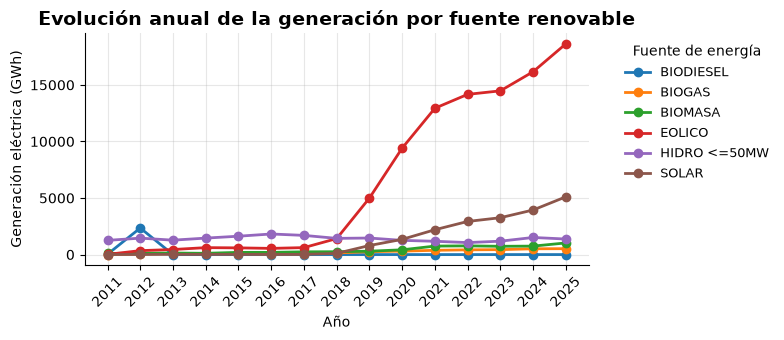

In [18]:

# Seleccionar únicamente años completos
fuentes_completas = generacion_por_fuente.loc[
    generacion_por_fuente.index <= 2025
]

# Gráfico de evolución por fuente energética
ax = fuentes_completas.plot(
    figsize=(8, 3.5),
    marker="o",
    linewidth=2
)

ax.set_title(
    "Evolución anual de la generación por fuente renovable",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Año")
ax.set_ylabel("Generación eléctrica (GWh)")

ax.set_xticks(fuentes_completas.index)
ax.tick_params(axis="x", rotation=45)

ax.grid(alpha=0.3)

ax.legend(
    title="Fuente de energía",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show();

### Evolución anual de la generación por fuente renovable

Se representa la evolución anual de la generación eléctrica de cada fuente renovable, expresada en GWh, durante el período 2011–2025.
El gráfico permite comparar el comportamiento de las distintas tecnologías, identificar tendencias de crecimiento o disminución y observar cuáles tuvieron mayor participación en la generación renovable.
Cada línea corresponde a una fuente energética diferente.
Para mantener una comparación consistente, se excluye el año 2026, debido a que los registros disponibles llegan solamente hasta agosto.

In [19]:
# Pregunta 1: ¿Qué fuente renovable muestra el mayor crecimiento?

# Seleccionar los años completos que queremos comparar
inicio = generacion_por_fuente.loc[2011]
final = generacion_por_fuente.loc[2025]

# Calcular el crecimiento absoluto en GWh
crecimiento = final - inicio

# Organizar los resultados en una tabla
tabla_crecimiento = (
    crecimiento
    .sort_values(ascending=False)
    .to_frame(name="Crecimiento absoluto (GWh)")
)

tabla_crecimiento


,Crecimiento absoluto (GWh)
FUENTE DE ENERGÍA,
EOLICO,"18.612,10"
SOLAR,"5.104,08"
BIOMASA,"931,95"
BIOGAS,"521,77"
HIDRO <=50MW,"118,65"
BIODIESEL,"-32,49"


### Pregunta 1: ¿Qué fuente renovable muestra el mayor crecimiento?

A partir del análisis de la generación anual de energías renovables en Argentina entre 2011 y 2025, se observa que **la energía eólica fue la fuente que presentó el mayor crecimiento absoluto**, con un incremento de **18.612,10 GWh**.
En segundo lugar se encuentra la energía solar, con un aumento de **5.104,08 GWh**, seguida de la biomasa (931,95 GWh), el biogás (521,77 GWh) y la hidráulica de pequeña escala (118,65 GWh).

Por otro lado, el biodiésel fue la única fuente que registró una disminución en su generación, con una variación de **-32,49 GWh**.
**Conclusión:** La energía eólica lideró ampliamente el crecimiento absoluto de la generación renovable durante el período analizado, seguida por la energía solar. Estos resultados muestran que ambas tecnologías fueron las principales responsables del aumento de generación registrado entre 2011 y 2025, dentro de las fuentes incluidas en el dataset.

In [20]:
# Pregunta 2: ¿Qué fuente presenta menor variación?

# Seleccionar años completos
fuentes_completas = generacion_por_fuente.loc[2011:2025]

# Calcular desviación estándar por fuente
estabilidad = fuentes_completas.std()

# Crear tabla ordenada
tabla_estabilidad = (
    estabilidad
    .sort_values()
    .to_frame(name="Desviación estándar (GWh)")
)

tabla_estabilidad

,Desviación estándar (GWh)
FUENTE DE ENERGÍA,
BIOGAS,"184,64"
HIDRO <=50MW,"208,39"
BIOMASA,"310,20"
BIODIESEL,"605,74"
SOLAR,"1.732,66"
EOLICO,"7.054,50"


### Pregunta 2: ¿Qué fuente renovable presenta la generación más estable?

A partir del cálculo de la desviación estándar de la generación anual entre 2011 y 2025, se observa que **el biogás presenta la menor variación absoluta**, con una desviación estándar de **184,64 GWh**.
En segundo lugar se encuentra la energía hidráulica de pequeña escala (208,39 GWh), seguida de la biomasa (310,20 GWh) y el biodiésel (605,74 GWh).
Por otro lado, la energía solar (1.732,66 GWh) y la eólica (7.054,50 GWh) presentan las mayores desviaciones estándar del período.

**Conclusión:** el biogás fue la fuente con menor variabilidad absoluta en su generación anual, mientras que la energía eólica registró la mayor dispersión.
Sin embargo, una desviación estándar elevada no significa necesariamente que una fuente sea inestable, ya que también puede reflejar un crecimiento importante de su generación a lo largo del tiempo.
Por lo tanto, estos resultados deben interpretarse considerando las diferencias de escala y las tendencias de crecimiento de cada tecnología.

In [21]:
# Pregunta 3: ¿Cuándo disminuyó la generación?

# Seleccionamos los años completos
fuentes_completas = generacion_por_fuente.loc[2011:2025]

# Calculamos las variaciones entre años consecutivos
variaciones = fuentes_completas.diff()

# Identificamos las 10 mayores caídas
caidas = variaciones.stack().nsmallest(10)

# Mostramos los resultados
tabla_caidas = caidas.to_frame(
    name="Variación anual (GWh)"
)

tabla_caidas


,,Variación anual (GWh)
AÑO,FUENTE DE ENERGÍA,
2013,BIODIESEL,"-2.348,12"
2018,HIDRO <=50MW,"-263,46"
2020,HIDRO <=50MW,"-205,22"
2013,HIDRO <=50MW,"-179,33"
2025,HIDRO <=50MW,"-137,54"
2017,HIDRO <=50MW,"-124,20"
2022,HIDRO <=50MW,"-114,93"
2021,HIDRO <=50MW,"-81,49"
2016,EOLICO,"-46,18"


### Pregunta 3: ¿Se observan caídas importantes en la generación entre años consecutivos?

A partir del análisis de las variaciones interanuales de generación renovable en Argentina durante el período 2011–2025, se identificaron disminuciones en distintas fuentes energéticas.
La **mayor caída se registró en el biodiésel durante 2013**, con una reducción de **2.348,12 GWh** respecto de 2012. Esta disminución fue considerablemente superior a las demás registradas en el análisis.
Por otro lado, la generación hidráulica de pequeña escala (HIDRO ≤50 MW) presentó disminuciones recurrentes en diferentes años. Entre las más importantes se encuentran 2018 (-263,46 GWh), 2020 (-205,22 GWh), 2013 (-179,33 GWh) y 2025 (-137,54 GWh).
También se identificaron disminuciones menores en la energía eólica durante 2016 (-46,18 GWh) y en la biomasa durante 2023 (-37,06 GWh).

**Conclusión:** El biodiésel registró la mayor caída interanual individual, mientras que la energía hidráulica de pequeña escala fue la fuente que apareció con mayor frecuencia entre las diez disminuciones absolutas más importantes.
Estos resultados muestran que la evolución de la generación renovable no fue uniforme entre las distintas tecnologías. Aunque algunas fuentes presentaron una tendencia de crecimiento a largo plazo, también experimentaron reducciones en determinados años.
Las variaciones identificadas permiten detectar períodos que requieren un análisis adicional, pero no permiten establecer por sí solas las causas de las disminuciones.

In [22]:
# Análisis geográfico de la generación por provincias

generacion_provincia = (
    df_original
    .groupby("PROVINCIA")["ENERGÍA GENERADA [GWh]"]
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="Generación total (GWh)")
)

generacion_provincia

,Generación total (GWh)
PROVINCIA,
BUENOS AIRES,"44.841,16"
CHUBUT,"42.353,15"
SAN JUAN,"11.034,43"
CORDOBA,"10.811,50"
SANTA CRUZ,"9.362,02"
SALTA,"6.458,31"
JUJUY,"6.350,03"
LA RIOJA,"6.187,27"
MENDOZA,"4.892,04"


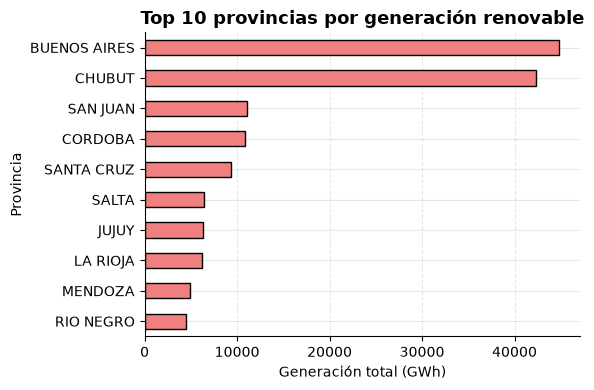

In [23]:
# Visualizar las 10 provincias con mayor generación renovable

top_10 = generacion_provincia.head(10)

ax = top_10.sort_values(
    "Generación total (GWh)",
    ascending=True
).plot(
    kind="barh",
    figsize=(6, 4),
    color="lightcoral",
    edgecolor="black",
    legend=False
)

ax.set_title(
    "Top 10 provincias por generación renovable",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Generación total (GWh)")
ax.set_ylabel("Provincia")

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show();

### Top 10 provincias con mayor generación renovable

Se representan mediante un gráfico de barras horizontales las diez provincias con mayor generación acumulada de energías renovables durante el período analizado.
El objetivo es identificar las provincias que concentran los mayores volúmenes de generación y comparar las diferencias existentes entre ellas.
Las provincias se ordenan de menor a mayor generación dentro del grupo seleccionado, facilitando la interpretación visual de los resultados.
La generación se expresa en GWh y corresponde a la suma de los registros disponibles para cada provincia.

In [24]:

#Ahora vamos a incorporar una herramienta nueva: pivot_table().
# ¿Qué fuente de energía predomina en cada provincia?

matriz_provincia = df_original.pivot_table(
    index="PROVINCIA",
    columns="FUENTE DE ENERGÍA",
    values="ENERGÍA GENERADA [GWh]",
    aggfunc="sum",
    fill_value=0
)

matriz_provincia

FUENTE DE ENERGÍA,BIODIESEL,BIOGAS,BIOMASA,EOLICO,HIDRO <=50MW,SOLAR
PROVINCIA,,,,,,
BUENOS AIRES,"2.360,84","2.190,43","0,81","40.273,36","0,00","15,72"
CATAMARCA,"0,00","0,00","0,00","0,00","0,00","1.182,26"
CHACO,"0,00","0,00","406,35","0,00","0,00","1.008,78"
CHUBUT,"0,00","0,00","0,00","40.497,01","1.856,14","0,00"
CORDOBA,"0,00","632,94","626,41","4.925,67","4.443,91","182,58"
CORRIENTES,"0,00","0,00","2.559,57","0,00","0,00","4,84"
FORMOSA,"0,00","0,00","0,00","0,00","0,00","33,76"
JUJUY,"0,00","0,00","0,00","0,00","1.560,14","4.789,89"
LA PAMPA,"0,00","64,56","0,00","1.259,86","316,05","36,47"


In [25]:
# Identificar la fuente predominante en cada provincia

fuente_predominante = matriz_provincia.idxmax(axis=1)

fuente_predominante.to_frame(
    name="Fuente predominante"
)

,Fuente predominante
PROVINCIA,
BUENOS AIRES,EOLICO
CATAMARCA,SOLAR
CHACO,SOLAR
CHUBUT,EOLICO
CORDOBA,EOLICO
CORRIENTES,BIOMASA
FORMOSA,SOLAR
JUJUY,SOLAR
LA PAMPA,EOLICO


In [26]:

# 1. Provincia con mayor generación renovable
provincia_lider = generacion_provincia.index[0]

# 2. Fuente principal de cada provincia
fuente_principal = matriz_provincia.idxmax(axis=1)

# 3. Provincia con mayor diversidad de fuentes
diversidad = (
    df_original
    .groupby("PROVINCIA")["FUENTE DE ENERGÍA"]
    .nunique()
)

# 4. Resumen de las respuestas
respuestas = pd.DataFrame({
    "Pregunta": [
        "¿Qué provincia genera más energía renovable?",
        "¿Qué fuente predomina en la provincia líder?",
        "¿Qué provincia tiene más fuentes distintas?"
    ],
    "Respuesta": [
        provincia_lider,
        fuente_principal.loc[provincia_lider],
        diversidad.idxmax()
    ]
})

respuestas


,Pregunta,Respuesta
0,¿Qué provincia genera más energía renovable?,BUENOS AIRES
1,¿Qué fuente predomina en la provincia líder?,EOLICO
2,¿Qué provincia tiene más fuentes distintas?,BUENOS AIRES


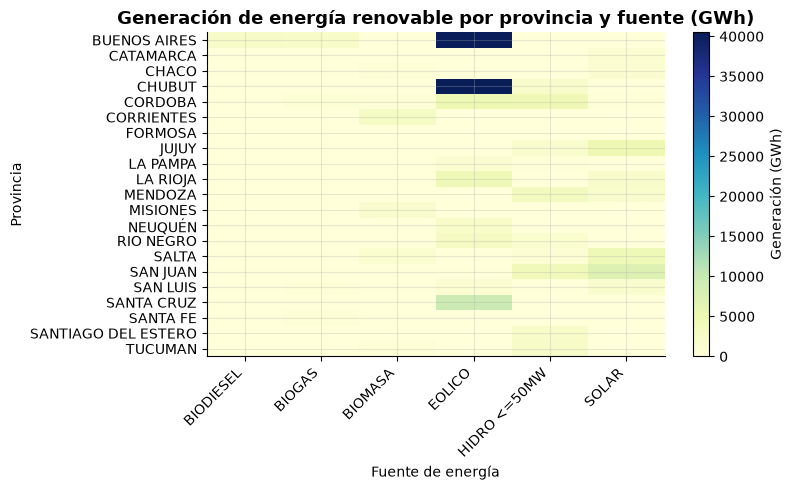

In [27]:
# Gráfico de mapa de calor para visualizar la generación por provincia y fuente de energía

fig, ax = plt.subplots(figsize=(8, 5))

imagen = ax.imshow(
    matriz_provincia,
    cmap="YlGnBu",
    aspect="auto"
)

# Etiquetas del eje X
ax.set_xticks(np.arange(len(matriz_provincia.columns)))
ax.set_xticklabels(
    matriz_provincia.columns,
    rotation=45,
    ha="right"
)

# Etiquetas del eje Y
ax.set_yticks(np.arange(len(matriz_provincia.index)))
ax.set_yticklabels(matriz_provincia.index)

# Título y etiquetas
ax.set_title(
    "Generación de energía renovable por provincia y fuente (GWh)",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Fuente de energía")
ax.set_ylabel("Provincia")

# Barra de color
fig.colorbar(
    imagen,
    ax=ax,
    label="Generación (GWh)"
)

plt.tight_layout()
plt.show();

1. Los líderes absolutos en Eólica: Buenos Aires y Chubut dominan completamente la matriz de generación eólica (son los dos bloques azul oscuro que saturan cerca de los 40.000 GWh). Esto tiene total coherencia geográfica e histórica por los vientos de la Patagonia y del sur bonaerense.
2. La distribución del resto de las fuentes: Se nota claramente que tecnologías como el Biodiésel y el Biogás están en un color amarillo muy claro uniforme, lo que indica que su generación acumulada es baja en comparación con la magnitud de la eólica.
3. Potencial Solar distribuido: Se observa actividad en el bloque Solar en provincias del NOA y Cuyo (como Jujuy, Salta y San Juan), apareciendo con tonos verdes tenues, marcando su crecimiento.


In [28]:
# Ranking de las 10 provincias por generación renovable

ranking_provincias = (
    matriz_provincia
    .assign(Total_GWh=matriz_provincia.sum(axis=1))
    .sort_values("Total_GWh", ascending=False)
)

ranking_provincias.head(10).round(2)

FUENTE DE ENERGÍA,BIODIESEL,BIOGAS,BIOMASA,EOLICO,HIDRO <=50MW,SOLAR,Total_GWh
PROVINCIA,,,,,,,
BUENOS AIRES,"2.360,84","2.190,43","0,81","40.273,36","0,00","15,72","44.841,16"
CHUBUT,"0,00","0,00","0,00","40.497,01","1.856,14","0,00","42.353,15"
SAN JUAN,"15,36","0,00","0,00","0,00","3.886,72","7.132,34","11.034,43"
CORDOBA,"0,00","632,94","626,41","4.925,67","4.443,91","182,58","10.811,50"
SANTA CRUZ,"0,00","0,00","0,00","9.362,02","0,00","0,00","9.362,02"
SALTA,"0,00","0,00","1.343,18","0,00","833,35","4.281,77","6.458,31"
JUJUY,"0,00","0,00","0,00","0,00","1.560,14","4.789,89","6.350,03"
LA RIOJA,"0,00","0,00","0,00","4.409,38","0,00","1.777,89","6.187,27"
MENDOZA,"3,53","0,00","0,00","0,00","3.316,74","1.571,77","4.892,04"


In [29]:
# Preguntas del análisis geográfico

respuestas_geograficas = pd.DataFrame({
    "Pregunta": [
        "¿Qué provincia genera más energía renovable?",
        "¿Qué provincia lidera la generación eólica?",
        "¿Cuál es la principal fuente de Buenos Aires?"
    ],
    "Respuesta": [
        ranking_provincias.index[0],
        matriz_provincia["EOLICO"].idxmax(),
        matriz_provincia.loc["BUENOS AIRES"].idxmax()
    ]
})

respuestas_geograficas

,Pregunta,Respuesta
0,¿Qué provincia genera más energía renovable?,BUENOS AIRES
1,¿Qué provincia lidera la generación eólica?,CHUBUT
2,¿Cuál es la principal fuente de Buenos Aires?,EOLICO


In [30]:
# Comparación de generación entre 2025 y 2026
# utilizando los mismos meses disponibles

# Identificar meses registrados en 2026
meses_2026 = df_temporal.loc[
    df_temporal["AÑO"] == 2026, "MesNumero"
].dropna().unique()

print("Meses disponibles en 2026:", sorted(meses_2026))

# Comparar la generación de ambos años
comparacion_2025_2026 = (
    df_temporal[
        df_temporal["AÑO"].isin([2025, 2026])
        & df_temporal["MesNumero"].isin(meses_2026)
    ]
    .groupby("AÑO")["ENERGÍA GENERADA [GWh]"]
    .sum()
    .to_frame("Generación comparable (GWh)")
)

comparacion_2025_2026


Meses disponibles en 2026: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8)]


,Generación comparable (GWh)
AÑO,
2025,"16.657,84"
2026,"17.505,86"


In [31]:

# Resumen de preguntas sobre cobertura temporal

respuestas_temporales = pd.DataFrame({
    "Pregunta": [
        "¿Cuántos meses tiene registrados 2025?",
        "¿Cuántos meses tiene registrados 2026?",
        "¿Podemos comparar directamente sus totales anuales?"
    ],
    "Respuesta": [
        cobertura_anual.loc[2025, "Meses_disponibles"],
        cobertura_anual.loc[2026, "Meses_disponibles"],
        (
            "No, tienen diferente cantidad de meses"
            if cobertura_anual.loc[2025, "Meses_disponibles"]
            != cobertura_anual.loc[2026, "Meses_disponibles"]
            else "Tienen igual cantidad; falta validar cobertura"
        )
    ]
})

respuestas_temporales


,Pregunta,Respuesta
0,¿Cuántos meses tiene registrados 2025?,12
1,¿Cuántos meses tiene registrados 2026?,8
2,¿Podemos comparar directamente sus totales anu...,"No, tienen diferente cantidad de meses"


In [32]:
# Calcular crecimiento entre períodos comparables

generacion_2025 = comparacion_2025_2026.loc[
    2025, "Generación comparable (GWh)"
]

generacion_2026 = comparacion_2025_2026.loc[
    2026, "Generación comparable (GWh)"
]

diferencia = generacion_2026 - generacion_2025

crecimiento_pct = (diferencia / generacion_2025) * 100

print(f"Diferencia: {diferencia:,.2f} GWh")
print(f"Crecimiento interanual: {crecimiento_pct:.2f}%")

Diferencia: 848.03 GWh
Crecimiento interanual: 5.09%


In [33]:
# Validación final de calidad de datos

print("Cantidad de registros:", len(df_original))

print("\nValores faltantes en columnas principales:")
columnas_clave = [
    "AÑO",
    "MES",
    "PROVINCIA",
    "FUENTE DE ENERGÍA",
    "ENERGÍA GENERADA [GWh]"
]

print(df_original[columnas_clave].isna().sum())

print("\nFilas duplicadas:")
print(df_original.duplicated().sum())

print("\nFechas inválidas:")
fechas = pd.to_datetime(df_original["MES"], errors="coerce")
print(fechas.isna().sum())

print("\nValores negativos de generación:")
print((df_original["ENERGÍA GENERADA [GWh]"] < 0).sum())

print("\nRegistros de Demanda MEM:")
print(
    df_original["FUENTE DE ENERGÍA"]
    .str.strip()
    .eq("Demanda MEM")
    .sum()
)

Cantidad de registros: 22868

Valores faltantes en columnas principales:
AÑO                       0
MES                       0
PROVINCIA                 0
FUENTE DE ENERGÍA         0
ENERGÍA GENERADA [GWh]    0
dtype: int64

Filas duplicadas:
0

Fechas inválidas:
0

Valores negativos de generación:
0

Registros de Demanda MEM:
0


### Validación final de calidad de datos

Antes de finalizar el análisis exploratorio, se realiza una comprobación adicional de la calidad del conjunto de datos.

Se examinan los valores faltantes, los registros duplicados, la validez de las fechas y los posibles valores negativos en la generación eléctrica.

El objetivo es detectar inconsistencias que puedan afectar la interpretación de los resultados y la preparación posterior de los modelos de Machine Learning.

In [34]:
# Revisar generación de biodiésel en 2012 y 2013

biodiesel_revision = df_originalalal[
    (df_original["FUENTE DE ENERGÍA"] == "BIODIESEL")
    & (df_limpio["AÑO"].isin([2012, 2013]))
]

resumen_biodiesel = (
    biodiesel_revision
    .groupby("AÑO")
    .agg(
        Registros=("ENERGÍA GENERADA [GWh]", "count"),
        Generacion_total=("ENERGÍA GENERADA [GWh]", "sum")
    )
)

resumen_biodiesel

NameError: name 'df_originalalal' is not defined

### Verificación de una caída significativa en la generación de biodiésel

Durante el análisis de variaciones interanuales se identificó una disminución de 2.348,12 GWh en la generación correspondiente a biodiésel durante 2013.

Debido a la magnitud de esta variación, se examinan los registros de 2012 y 2013 para comprobar los valores anuales y la cantidad de observaciones disponibles.

Esta revisión busca distinguir entre una variación registrada en los datos y una posible inconsistencia en la información.

In [ ]:
# Preparar la serie mensual para su validación

df_mensual = df_limpio.copy()

df_mensual["MES"] = pd.to_datetime(
    df_mensual["MES"],
    errors="coerce"
)

df_mensual = (
    df_mensual.dropna(subset=["MES"])
    .groupby("MES", as_index=False)["ENERGÍA GENERADA [GWh]"]
    .sum()
    .sort_values("MES")
)

# Seleccionar años completos
serie_completa = df_mensual[
    df_mensual["MES"].dt.year <= 2025
].copy()

# Verificar meses faltantes
meses_esperados = pd.date_range(
    start="2011-01-01",
    end="2025-12-01",
    freq="MS"
)

meses_faltantes = meses_esperados.difference(
    serie_completa["MES"]
)

print("Meses esperados:", len(meses_esperados))
print("Meses registrados:", len(serie_completa))
print("Meses faltantes:", len(meses_faltantes))

print("\nPeríodos faltantes:")
print(meses_faltantes)

Meses esperados: 180
Meses registrados: 180
Meses faltantes: 0

Períodos faltantes:
DatetimeIndex([], dtype='datetime64[us]', freq='MS')


## Conclusión del Análisis Exploratorio de Datos (EDA)

El Análisis Exploratorio de Datos (EDA) permitió comprender el comportamiento de la generación de energías renovables en Argentina durante el período 2011–2026.
Mediante el uso de **Python, Pandas, NumPy y Matplotlib**, se realizaron tareas de limpieza, agrupación, análisis estadístico y visualización de datos.
Se identificó un crecimiento significativo de la generación renovable entre 2011 y 2025, destacándose la **energía eólica como la fuente de mayor crecimiento absoluto**, seguida por la energía solar.
También se analizaron las variaciones anuales, la estabilidad de las diferentes fuentes energéticas y la distribución de la generación por provincias.
Finalmente, se verificó la cobertura temporal del dataset, identificando que los años 2011–2025 cuentan con registros de los doce meses, mientras que 2026 contiene información hasta agosto.

**En conclusión**, el EDA permitió identificar tendencias, patrones y diferencias en la generación renovable, además de verificar la calidad y continuidad temporal de los datos.
Estos resultados constituyen la base para la siguiente etapa del proyecto: **la construcción y evaluación de modelos predictivos mediante Machine Learning**.

# Machine Learning — Predicción de la Generación de Energías Renovables
## Introducción
En esta etapa del proyecto se aplicarán técnicas de **Machine Learning (aprendizaje automático)** para desarrollar modelos capaces de predecir la generación mensual de energías renovables en Argentina.
A partir de los datos históricos previamente analizados y depurados durante el EDA, se construirá una serie temporal y se prepararán variables predictoras relacionadas con los meses anteriores, la estacionalidad y la evolución de la generación.

### Objetivos

- Preparar los datos para el entrenamiento de modelos predictivos.
- Crear variables temporales (*lags*) para utilizar información de meses anteriores.
- Dividir los datos en entrenamiento y prueba, respetando el orden cronológico.
- Entrenar y comparar modelos como **Regresión Lineal, Ridge, Lasso y Random Forest**.
- Evaluar el rendimiento mediante métricas como **MAE, RMSE y R²**.
- Analizar los errores y seleccionar el modelo con mejor capacidad de generalización.

### Metodología

Se utilizará la biblioteca **Scikit-learn** de Python para entrenar y evaluar los modelos.
Debido a que trabajamos con datos temporales, no se realizará una división aleatoria, sino cronológica, evitando utilizar información futura para predecir valores del pasado.
El objetivo final será identificar qué modelo logra estimar con mayor precisión la generación mensual de energía renovable y comprender las limitaciones de sus predicciones.

In [ ]:
#Generacion_GWh: variable que queremos predecir.
#Generacion_mes_anterior: dato que utilizaremos para realizar la predicción.


# 1. Preparar los datos de generación renovable
df_ordenado = df_original.copy()

# Convertir MES a formato fecha
df_ordenado["MES"] = pd.to_datetime(df_ordenado["MES"])

# 2. Agrupar la generación total por mes
df_ml = (
    df_ordenado
    .groupby("MES")["ENERGÍA GENERADA [GWh]"]
    .sum()
    .sort_index()
    .to_frame()
)

# 3. Renombrar la variable objetivo
df_ml.columns = ["Generacion_GWh"]

# 4. Crear la variable predictora del mes anterior
df_ml["Generacion_mes_anterior"] = (
    df_ml["Generacion_GWh"].shift(1)
)

# 5. Eliminar la primera fila sin dato anterior
df_ml = df_ml.dropna()

# 6. Mostrar los resultados
df_ml.head(10)


,Generacion_GWh,Generacion_mes_anterior
MES,,
2011-02-01,"130,17","121,25"
2011-03-01,"149,25","130,17"
2011-04-01,"134,88","149,25"
2011-05-01,"101,28","134,88"
2011-06-01,"77,39","101,28"
2011-07-01,"81,10","77,39"
2011-08-01,"95,77","81,10"
2011-09-01,"114,63","95,77"
2011-10-01,"123,57","114,63"


In [ ]:
# Verificar continuidad mensual
meses_esperados = pd.date_range(
    df_ml.index.min(),
    df_ml.index.max(),
    freq="MS"
)

print("Meses faltantes:",
      len(meses_esperados.difference(df_ml.index)))

print("Primer mes:", df_ml.index.min())
print("Último mes:", df_ml.index.max())

Meses faltantes: 0
Primer mes: 2011-02-01 00:00:00
Último mes: 2026-08-01 00:00:00


In [ ]:

# Variables del primer modelo de Regresión Lineal

X = df_ml[["Generacion_mes_anterior"]].copy()
y = df_ml["Generacion_GWh"].copy()

# Separación cronológica
X_train = X.loc[:"2024-12-01"]
X_test = X.loc["2025-01-01":"2025-12-01"]

y_train = y.loc[:"2024-12-01"]
y_test = y.loc["2025-01-01":"2025-12-01"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Columnas:", X_test.columns.tolist())

X_train: (167, 1)
X_test: (12, 1)
Columnas: ['Generacion_mes_anterior']


In [ ]:
# Separación cronológica de entrenamiento y prueba

# Datos para entrenamiento: hasta diciembre de 2024
X_train = X.loc[:"2024-12-01"]
y_train = y.loc[:"2024-12-01"]

# Datos para prueba: enero a diciembre de 2025
X_test = X.loc["2025-01-01":"2025-12-01"]
y_test = y.loc["2025-01-01":"2025-12-01"]

# Verificar la división
print("Entrenamiento:", len(X_train), "meses")
print("Prueba:", len(X_test), "meses")

print("Último mes de entrenamiento:", X_train.index.max())
print("Primer mes de prueba:", X_test.index.min())

Entrenamiento: 167 meses
Prueba: 12 meses
Último mes de entrenamiento: 2024-12-01 00:00:00
Primer mes de prueba: 2025-01-01 00:00:00


In [ ]:
# Evaluamos el modelo de Regresión Lineal
modelo = LinearRegression()

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f} GWh")
print(f"RMSE: {rmse:.2f} GWh")
print(f"R²: {r2:.3f}")



MAE: 131.52 GWh
RMSE: 175.53 GWh
R²: 0.349


### Evaluación del modelo de Regresión Lineal

Para evaluar el rendimiento del modelo predictivo se utilizan tres métricas estadísticas:

- **MAE (Error Absoluto Medio):** mide la diferencia absoluta promedio entre los valores reales y las predicciones, expresada en GWh.
- **RMSE (Raíz del Error Cuadrático Medio):** mide la magnitud de los errores y penaliza especialmente las predicciones con desviaciones elevadas.
- **R² (Coeficiente de Determinación):** permite evaluar el rendimiento del modelo en comparación con una predicción constante basada en la media de los valores reales.

Las métricas se calculan utilizando los doce meses del conjunto de prueba correspondiente a 2025.
El objetivo es conocer la capacidad predictiva de la Regresión Lineal antes de compararla con otros métodos.

In [ ]:
# Comparación con una predicción naive
# Suponemos que cada mes genera lo mismo que el anterior

y_pred_naive = X_test["Generacion_mes_anterior"]

comparacion_modelos = pd.DataFrame({
    "Modelo": ["Regresión Lineal", "Naive"],
    "MAE": [
        mae,
        mean_absolute_error(y_test, y_pred_naive)
    ],
    "RMSE": [
        rmse,
        np.sqrt(mean_squared_error(y_test, y_pred_naive))
    ],
    "R²": [
        r2,
        r2_score(y_test, y_pred_naive)
    ]
})

comparacion_modelos.round(3)

,Modelo,MAE,RMSE,R²
0,Regresión Lineal,"131,52","175,53","0,35"
1,Naive,"133,69","177,28","0,34"


In [ ]:
# SEGUNDO MODELO: REGRESIÓN LINEAL CON 3 LAGS

# 1. Preparar la serie mensual original
df_nuevo = (
    df_original
    .assign(MES=lambda df: pd.to_datetime(df["MES"]))
    .groupby("MES")["ENERGÍA GENERADA [GWh]"]
    .sum()
    .sort_index()
    .to_frame(name="Generacion_GWh")
)

# 2. Crear variables temporales
df_nuevo["lag_1"] = df_nuevo["Generacion_GWh"].shift(1)
df_nuevo["lag_2"] = df_nuevo["Generacion_GWh"].shift(2)
df_nuevo["lag_3"] = df_nuevo["Generacion_GWh"].shift(3)

# 3. Eliminar filas sin información de los 3 meses anteriores
df_nuevo = df_nuevo.dropna(
    subset=["Generacion_GWh", "lag_1", "lag_2", "lag_3"]
)

# 4. Definir variables del segundo modelo
X_3lags = df_nuevo[["lag_1", "lag_2", "lag_3"]]
y_3lags = df_nuevo["Generacion_GWh"]

# 5. Separación cronológica
X_train_3lags = X_3lags.loc[:"2024-12-01"]
X_test_3lags = X_3lags.loc["2025-01-01":"2025-12-01"]

y_train_3lags = y_3lags.loc[:"2024-12-01"]
y_test_3lags = y_3lags.loc["2025-01-01":"2025-12-01"]

# 6. Entrenar el segundo modelo
modelo_3lags = LinearRegression()
modelo_3lags.fit(X_train_3lags, y_train_3lags)

# 7. Realizar predicciones
y_pred_3lags = modelo_3lags.predict(X_test_3lags)

# 8. Evaluar
mae_3lags = mean_absolute_error(y_test_3lags, y_pred_3lags)

print("Entrenamiento:", len(X_train_3lags), "meses")
print("Prueba:", len(X_test_3lags), "meses")
print(f"MAE modelo 3 lags: {mae_3lags:.2f} GWh")



Entrenamiento: 165 meses
Prueba: 12 meses
MAE modelo 3 lags: 122.09 GWh


### Resultados de la Regresión Lineal con tres lags

El segundo modelo de Regresión Lineal se entrenó utilizando 165 meses de información histórica y tres variables temporales correspondientes a la generación de los meses anteriores.
La evaluación sobre los 12 meses de 2025 arrojó un **MAE de 122,09 GWh**.
En comparación, el primer modelo de Regresión Lineal, que utilizaba un solo mes anterior, había obtenido un MAE de 131,52 GWh.
Esto representa una reducción del error absoluto medio de **9,43 GWh, equivalente aproximadamente al 7,2 %**.

**Conclusión:** la incorporación de tres rezagos temporales mejoró la precisión promedio de las predicciones durante el período evaluado. No obstante, será necesario comprobar la consistencia de esta mejora mediante validación temporal antes de seleccionar una configuración definitiva.

In [ ]:

# COMPARACIÓN DE MODELOS - SIN SOBRESCRIBIR VARIABLES

# 1. Datos de prueba de 2025
X_test_1lag = df_ml.loc[
    "2025-01-01":"2025-12-01",
    ["Generacion_mes_anterior"]
]

y_test_1lag = df_ml.loc[
    "2025-01-01":"2025-12-01",
    "Generacion_GWh"
]

# 2. Entrenar nuevamente el primer modelo
X_train_1lag = df_ml.loc[
    :"2024-12-01",
    ["Generacion_mes_anterior"]
]

y_train_1lag = df_ml.loc[
    :"2024-12-01",
    "Generacion_GWh"
]

modelo_1lag = LinearRegression()
modelo_1lag.fit(X_train_1lag, y_train_1lag)

# 3. Obtener predicciones
pred_1lag = modelo_1lag.predict(X_test_1lag)

# 4. Calcular errores
mae_1lag = mean_absolute_error(y_test_1lag, pred_1lag)

mae_naive = mean_absolute_error(
    y_test_1lag,
    X_test_1lag["Generacion_mes_anterior"]
)

# 5. Tabla comparativa
comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Naive",
        "Regresión Lineal - 1 lag",
        "Regresión Lineal - 3 lags"
    ],
    "MAE (GWh)": [
        mae_naive,
        mae_1lag,
        mae_3lags
    ]
})

comparacion_modelos.round(2)

,Modelo,MAE (GWh)
0,Naive,"133,69"
1,Regresión Lineal - 1 lag,"131,52"
2,Regresión Lineal - 3 lags,"122,09"


### Comparación de modelos predictivos iniciales

Se compararon tres métodos para predecir la generación mensual de energías renovables: un modelo Naive, una Regresión Lineal con un rezago temporal y una Regresión Lineal con tres rezagos.
Los modelos obtuvieron errores absolutos medios (MAE) de 133,69 GWh, 131,52 GWh y 122,09 GWh, respectivamente.

**El modelo de Regresión Lineal con tres lags presentó el menor error durante 2025**, reduciendo el MAE aproximadamente un 7,2 % respecto a la regresión con un solo lag.
Estos resultados sugieren que incorporar información de varios meses anteriores puede mejorar las predicciones. Sin embargo, será necesario utilizar validación temporal para evaluar si esta mejora se mantiene en diferentes períodos.

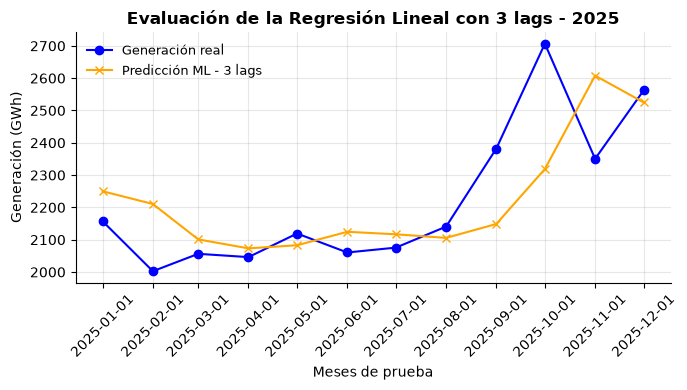

In [ ]:

# Comparación de valores reales y predicciones - Modelo 3 lags

plt.figure(figsize=(7, 4))

plt.plot(
    y_test_3lags.index,
    y_test_3lags.values,
    label="Generación real",
    marker="o",
    color="blue"
)

plt.plot(
    y_test_3lags.index,
    y_pred_3lags,
    label="Predicción ML - 3 lags",
    marker="x",
    color="orange"
)

plt.title("Evaluación de la Regresión Lineal con 3 lags - 2025")
plt.xlabel("Meses de prueba")
plt.ylabel("Generación (GWh)")

plt.xticks(y_test_3lags.index, rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show();

### Comparación visual de predicciones — Regresión Lineal con tres lags

Se comparan los valores reales de generación renovable durante 2025 con las predicciones obtenidas mediante el modelo de Regresión Lineal que utiliza tres rezagos temporales.
El objetivo es observar qué tan bien el modelo reproduce las variaciones mensuales e identificar los períodos en los que se presentan mayores diferencias entre la generación real y la estimada.
Este modelo obtuvo un **MAE de 122,09 GWh**, inferior al registrado por la Regresión Lineal con un solo lag (131,52 GWh).
La comparación gráfica permitirá complementar las métricas estadísticas y analizar el comportamiento de las predicciones.

In [ ]:
# Analizamos los errores del modelo de 3 lags

resultados_3lags = pd.DataFrame({
    "Real_GWh": y_test_3lags.values,
    "Prediccion_GWh": y_pred_3lags
}, index=y_test_3lags.index)

# Calculamos el error absoluto
resultados_3lags["Error_absoluto"] = abs(
    resultados_3lags["Real_GWh"] -
    resultados_3lags["Prediccion_GWh"]
)

# Mostrar los primeros 10 resultados
resultados_3lags.head(10).round(2)

,Real_GWh,Prediccion_GWh,Error_absoluto
MES,,,
2025-01-01,"2.157,01","2.249,95","92,94"
2025-02-01,"2.002,53","2.210,56","208,03"
2025-03-01,"2.056,35","2.100,95","44,59"
2025-04-01,"2.046,15","2.073,23","27,07"
2025-05-01,"2.119,20","2.082,88","36,32"
2025-06-01,"2.060,51","2.124,52","64,00"
2025-07-01,"2.075,50","2.116,77","41,27"
2025-08-01,"2.140,58","2.105,65","34,93"
2025-09-01,"2.381,95","2.148,66","233,29"


In [ ]:
# Identificar los 5 meses con mayores errores

peores_3lags = resultados_3lags.nlargest(
    5, "Error_absoluto"
)

peores_3lags.round(2)

,Real_GWh,Prediccion_GWh,Error_absoluto
MES,,,
2025-10-01,"2.706,63","2.318,91","387,72"
2025-11-01,"2.350,48","2.607,87","257,39"
2025-09-01,"2.381,95","2.148,66","233,29"
2025-02-01,"2.002,53","2.210,56","208,03"
2025-01-01,"2.157,01","2.249,95","92,94"


In [ ]:
# Calcular los residuos del modelo de 3 lags

resultados_3lags["Residuo"] = (
    resultados_3lags["Real_GWh"] -
    resultados_3lags["Prediccion_GWh"]
)

resultados_3lags.head(10).round(2)

,Real_GWh,Prediccion_GWh,Error_absoluto,Residuo
MES,,,,
2025-01-01,"2.157,01","2.249,95","92,94","-92,94"
2025-02-01,"2.002,53","2.210,56","208,03","-208,03"
2025-03-01,"2.056,35","2.100,95","44,59","-44,59"
2025-04-01,"2.046,15","2.073,23","27,07","-27,07"
2025-05-01,"2.119,20","2.082,88","36,32","36,32"
2025-06-01,"2.060,51","2.124,52","64,00","-64,00"
2025-07-01,"2.075,50","2.116,77","41,27","-41,27"
2025-08-01,"2.140,58","2.105,65","34,93","34,93"
2025-09-01,"2.381,95","2.148,66","233,29","233,29"


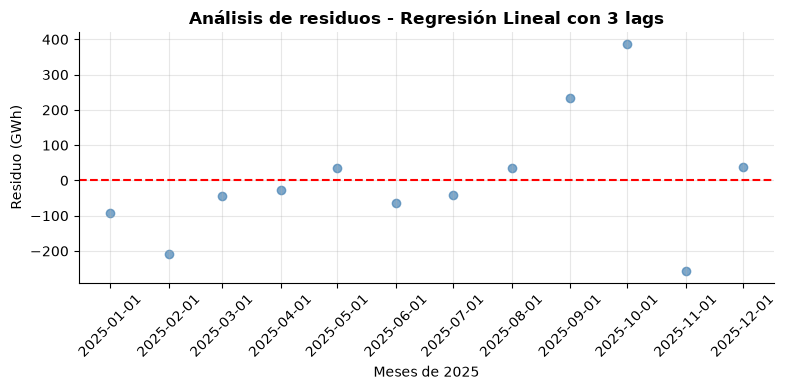

In [ ]:
# Gráfico de residuos del modelo con 3 lags

plt.figure(figsize=(8, 4))

plt.scatter(
    resultados_3lags.index,
    resultados_3lags["Residuo"],
    color="steelblue",
    alpha=0.7
)

# Línea de referencia en cero
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Análisis de residuos - Regresión Lineal con 3 lags")
plt.xlabel("Meses de 2025")
plt.ylabel("Residuo (GWh)")

plt.xticks(resultados_3lags.index, rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show();

### Visualización de residuos de la Regresión Lineal con tres lags

Se representa gráficamente la distribución temporal de los residuos del modelo durante los doce meses de 2025.
La línea horizontal roja representa el valor cero, que corresponde a una predicción sin error.
Los valores positivos indican subestimaciones, mientras que los negativos representan sobreestimaciones de la generación renovable.
El objetivo es identificar posibles patrones, errores elevados y períodos en los que el modelo presenta mayores dificultades predictivas.
Esta visualización complementa el análisis del MAE y permite evaluar el comportamiento de los errores a lo largo del tiempo.

In [ ]:
# Análisis del sesgo del modelo con 3 lags

# 1. Calcular el sesgo promedio
sesgo_3lags = resultados_3lags["Residuo"].mean()

# 2. Contar sobreestimaciones y subestimaciones
sobreestimaciones = (
    resultados_3lags["Residuo"] < 0
).sum()

subestimaciones = (
    resultados_3lags["Residuo"] > 0
).sum()

# 3. Mostrar los resultados
print(f"Sesgo promedio: {sesgo_3lags:.2f} GWh")
print("Sobreestimaciones:", sobreestimaciones)
print("Subestimaciones:", subestimaciones)


Sesgo promedio: -0.46 GWh
Sobreestimaciones: 7
Subestimaciones: 5


### Resultados del análisis de sesgo — Regresión Lineal con tres lags

El análisis de los residuos del modelo durante 2025 arrojó un **sesgo promedio de −0,46 GWh**, lo que indica una ligera tendencia general a sobreestimar la generación renovable.
De las doce predicciones realizadas, siete fueron sobreestimaciones y cinco subestimaciones.
Aunque el sesgo promedio fue cercano a cero, el modelo presentó un MAE de 122,09 GWh. Esto demuestra que los errores positivos y negativos pueden compensarse, incluso cuando existen diferencias importantes entre los valores reales y las predicciones.

**Conclusión:** el modelo no presentó un sesgo promedio elevado durante el período evaluado, pero todavía mostró dificultades para predecir determinados cambios pronunciados en la generación mensual.

In [ ]:
# Evaluación final - Regresión Lineal con 3 lags

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

mae_final_lineal = mean_absolute_error(
    y_test_3lags, y_pred_3lags
)

rmse_final_lineal = np.sqrt(
    mean_squared_error(y_test_3lags, y_pred_3lags)
)

r2_final_lineal = r2_score(
    y_test_3lags, y_pred_3lags
)

sesgo_final_lineal = np.mean(
    y_test_3lags.to_numpy() - y_pred_3lags
)

evaluacion_final = pd.DataFrame({
    "Métrica": [
        "MAE (GWh)",
        "RMSE (GWh)",
        "R²",
        "Residuo promedio (GWh)"
    ],
    "Resultado": [
        mae_final_lineal,
        rmse_final_lineal,
        r2_final_lineal,
        sesgo_final_lineal
    ]
})

evaluacion_final.round(3)

,Métrica,Resultado
0,MAE (GWh),"122,09"
1,RMSE (GWh),"167,18"
2,R²,"0,41"
3,Residuo promedio (GWh),"-0,46"


### Interpretación de las métricas finales

La Regresión Lineal con tres rezagos temporales obtuvo un **MAE de 122,09 GWh** y un **RMSE de 167,18 GWh** en la evaluación correspondiente a 2025.
La diferencia entre ambas métricas indica la presencia de algunos errores de predicción relativamente elevados.
El coeficiente de determinación **R² fue de 0,41**, lo que representa un rendimiento superior al de una predicción constante basada en la media del período, aunque el modelo todavía presenta limitaciones para reproducir las fluctuaciones mensuales.
El residuo promedio fue de **−0,46 GWh**, indicando una compensación casi completa entre sobreestimaciones y subestimaciones.
En conjunto, estos resultados muestran que la Regresión Lineal con tres rezagos constituye la alternativa más favorable entre las configuraciones evaluadas, aunque conserva errores relevantes y requiere actualizaciones mensuales de los datos observados para realizar nuevas predicciones.
La evaluación de 2025 se considera exploratoria porque sus resultados también fueron consultados durante el desarrollo y comparación de modelos.

In [ ]:
# Crear una copia para conservar las variables originales
X_train_ciclico = X_train_3lags.copy()

# Obtener el número de mes desde el índice de fechas
mes = X_train_ciclico.index.month

# Crear las variables estacionales
X_train_ciclico["mes_sin"] = np.sin(2 * np.pi * mes / 12)
X_train_ciclico["mes_cos"] = np.cos(2 * np.pi * mes / 12)

# Mostrar las primeras observaciones
display(X_train_ciclico.head())

,lag_1,lag_2,lag_3,mes_sin,mes_cos
MES,,,,,
2011-04-01,"149,25","130,17","121,25","0,87","-0,50"
2011-05-01,"134,88","149,25","130,17","0,50","-0,87"
2011-06-01,"101,28","134,88","149,25","0,00","-1,00"
2011-07-01,"77,39","101,28","134,88","-0,50","-0,87"
2011-08-01,"81,10","77,39","101,28","-0,87","-0,50"


## Preparación de datos para modelos con estacionalidad

### Objetivo
Incorporar las variables cíclicas `mes_sin` y `mes_cos` tanto
al conjunto de entrenamiento como al conjunto de prueba.

### Metodología
Se utilizarán cinco variables predictoras:

- lag_1: generación del mes anterior.
- lag_2: generación de dos meses anteriores.
- lag_3: generación de tres meses anteriores.
- mes_sin: componente seno del mes.
- mes_cos: componente coseno del mes.

Las características estacionales se calcularán utilizando
exclusivamente las fechas correspondientes a cada observación.
Se conservará la división cronológica original:
- Entrenamiento: hasta diciembre de 2024.
- Prueba: enero a diciembre de 2025.
Esta metodología permite comparar los modelos bajo las
mismas condiciones, evitando utilizar información futura
durante el entrenamiento.

In [ ]:
# Crear una copia del conjunto de prueba
X_test_ciclico = X_test_3lags.copy()

# Obtener el número del mes
mes_test = X_test_ciclico.index.month

# Incorporar las variables cíclicas
X_test_ciclico["mes_sin"] = np.sin(
    2 * np.pi * mes_test / 12
)

X_test_ciclico["mes_cos"] = np.cos(
    2 * np.pi * mes_test / 12
)

# Comprobar que ambos conjuntos tengan las mismas columnas
assert X_train_ciclico.columns.equals(X_test_ciclico.columns)

# Visualizar el conjunto de prueba
display(X_test_ciclico.head())

,lag_1,lag_2,lag_3,mes_sin,mes_cos
MES,,,,,
2025-01-01,"2.196,84","2.250,54","2.087,31","0,50","0,87"
2025-02-01,"2.157,01","2.196,84","2.250,54","0,87","0,50"
2025-03-01,"2.002,53","2.157,01","2.196,84","1,00","0,00"
2025-04-01,"2.056,35","2.002,53","2.157,01","0,87","-0,50"
2025-05-01,"2.046,15","2.056,35","2.002,53","0,50","-0,87"


## Optimización de Ridge Regression con estacionalidad

### Objetivo
Evaluar si la incorporación de variables estacionales
mejora la precisión del modelo Ridge para predecir
la generación eléctrica renovable mensual.
### Metodología
Se utilizarán cinco variables predictoras:
- lag_1
- lag_2
- lag_3
- mes_sin
- mes_cos
El modelo Ridge aplica regularización L2, que penaliza
coeficientes elevados para controlar la complejidad
del modelo y reducir el riesgo de sobreajuste.
### Optimización
Se utilizará GridSearchCV para encontrar el mejor
valor del hiperparámetro alpha.
La evaluación de hiperparámetros se realizará mediante
TimeSeriesSplit, respetando el orden cronológico.
### Evaluación del modelo
El rendimiento se medirá mediante:
- MAE: error absoluto medio.
- RMSE: raíz del error cuadrático medio.
- R²: coeficiente de determinación.
Finalmente, se compararán los resultados con los
obtenidos anteriormente sin variables estacionales.

In [ ]:

# Crear el pipeline de Ridge
pipeline_ridge_ciclico = make_pipeline(
    StandardScaler(),
    Ridge()
)

# Definir los valores de alpha que vamos a evaluar
parametros_ridge = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Buscar la mejor configuración mediante validación temporal
busqueda_ridge_ciclico = GridSearchCV(
    estimator=pipeline_ridge_ciclico,
    param_grid=parametros_ridge,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=1
)

# Entrenar utilizando solamente los datos de entrenamiento
busqueda_ridge_ciclico.fit(
    X_train_ciclico,
    y_train_3lags
)

# Mostrar resultados de la optimización
resultados_ridge_cv = pd.DataFrame(
    busqueda_ridge_ciclico.cv_results_
)[[
    "param_ridge__alpha",
    "mean_test_score",
    "std_test_score"
]].copy()

resultados_ridge_cv["MAE_CV"] = (
    -resultados_ridge_cv["mean_test_score"]
)

display(
    resultados_ridge_cv[
        ["param_ridge__alpha", "MAE_CV", "std_test_score"]
    ].sort_values("MAE_CV").round(2)
)

,param_ridge__alpha,MAE_CV,std_test_score
2,"1,00","69,01","45,33"
1,"0,10","69,81","45,94"
0,"0,01","69,97","46,09"
3,"10,00","71,42","46,69"
4,"100,00","146,36","105,16"
5,"1.000,00","425,24","380,32"


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generar predicciones sobre 2025
pred_ridge_ciclico = busqueda_ridge_ciclico.predict(
    X_test_ciclico
)

# Calcular métricas
mae_ridge_ciclico = mean_absolute_error(
    y_test_3lags,
    pred_ridge_ciclico
)

rmse_ridge_ciclico = np.sqrt(
    mean_squared_error(
        y_test_3lags,
        pred_ridge_ciclico
    )
)

r2_ridge_ciclico = r2_score(
    y_test_3lags,
    pred_ridge_ciclico
)

# Presentar resultados
metricas_ridge_ciclico = pd.DataFrame({
    "Modelo": ["Ridge con estacionalidad"],
    "Mejor_alpha": [
        busqueda_ridge_ciclico.best_params_["ridge__alpha"]
    ],
    "MAE_CV": [-busqueda_ridge_ciclico.best_score_],
    "MAE_2025": [mae_ridge_ciclico],
    "RMSE_2025": [rmse_ridge_ciclico],
    "R2_2025": [r2_ridge_ciclico]
})

display(metricas_ridge_ciclico.round(3))

,Modelo,Mejor_alpha,MAE_CV,MAE_2025,RMSE_2025,R2_2025
0,Ridge con estacionalidad,1,"69,01","105,77","149,82","0,53"


### Interpretación de resultados: Ridge con estacionalidad

El modelo Ridge con variables cíclicas obtuvo los
siguientes resultados:
- Alpha óptimo: 1
- MAE de validación temporal: 69,01 GWh
- MAE en prueba 2025: 105,77 GWh
- RMSE en prueba 2025: 149,82 GWh
- R² en prueba 2025: 0,53
El coeficiente R² indica que el modelo explica
aproximadamente el 53 % de la variabilidad de la
generación mensual observada durante 2025.
El MAE de 105,77 GWh representa la desviación
absoluta promedio entre las predicciones y los
valores reales.
La diferencia entre el MAE de validación histórica
y el MAE de 2025 indica un deterioro del rendimiento
en el período de prueba.
La incorporación de variables cíclicas permite
representar la estacionalidad anual dentro del modelo.
Sin embargo, para determinar si estas variables
mejoraron efectivamente las predicciones, es
necesario comparar Ridge con y sin estacionalidad
bajo el mismo protocolo de evaluación.
Estos resultados corresponden a pronósticos
mensuales de un paso adelante y no garantizan
la precisión de proyecciones hasta 2030.

In [ ]:
# Modelo operativo: reentrenar Ridge con todos los meses disponibles hasta agosto de 2026.
# Usamos el alpha seleccionado con validación temporal antes de evaluar 2025.
from sklearn.base import clone
datos_operativos = df_nuevo.loc[:"2026-08-01"].copy()
meses_op = datos_operativos.index.month
X_operativo = datos_operativos[["lag_1", "lag_2", "lag_3"]].copy()
X_operativo["mes_sin"] = np.sin(2*np.pi*meses_op/12)
X_operativo["mes_cos"] = np.cos(2*np.pi*meses_op/12)
y_operativo = datos_operativos["Generacion_GWh"]
modelo_operativo = clone(busqueda_ridge_ciclico.best_estimator_)
modelo_operativo.fit(X_operativo, y_operativo)
print("Ridge reentrenado hasta:", datos_operativos.index.max().date())


Ridge reentrenado hasta: 2026-08-01


In [ ]:
# Pronóstico mensual Ridge. No es una predicción multianual.
pred_septiembre = float(modelo_operativo.predict(X_septiembre)[0])
print(f"Estimación Ridge para septiembre de 2026: {pred_septiembre:,.2f} GWh")


Estimación Ridge para septiembre de 2026: 2,136.68 GWh


In [ ]:
# Comparación del pronóstico con los últimos meses reales

comparacion_pronostico = pd.DataFrame({
    "Mes": [
        "Junio 2026",
        "Julio 2026",
        "Agosto 2026",
        "Septiembre 2026 (predicción)"
    ],
    "Generacion_GWh": [
        ultimos_3_meses.iloc[-3],
        ultimos_3_meses.iloc[-2],
        ultimos_3_meses.iloc[-1],
        pred_septiembre
    ]
})

comparacion_pronostico.round(2)

,Mes,Generacion_GWh
0,Junio 2026,"2.062,79"
1,Julio 2026,"1.791,25"
2,Agosto 2026,"2.269,65"
3,Septiembre 2026 (predicción),"2.136,68"


In [ ]:
# Modelo baseline: persistencia mensual

pred_persistencia = X_test_3lags["lag_1"].to_numpy()

# Calcular métricas
mae_persistencia = mean_absolute_error(
    y_test_3lags,
    pred_persistencia
)

rmse_persistencia = np.sqrt(
    mean_squared_error(
        y_test_3lags,
        pred_persistencia
    )
)

r2_persistencia = r2_score(
    y_test_3lags,
    pred_persistencia
)

# Crear tabla
metricas_persistencia = pd.DataFrame({
    "Modelo": ["Persistencia mensual"],
    "MAE_2025": [mae_persistencia],
    "RMSE_2025": [rmse_persistencia],
    "R2_2025": [r2_persistencia]
})

display(metricas_persistencia.round(3))

,Modelo,MAE_2025,RMSE_2025,R2_2025
0,Persistencia mensual,"133,69","177,28","0,34"


In [ ]:
# Tabla final de métodos: misma prueba de enero a diciembre de 2025.
# La persistencia es referencia; la regresión lineal y Ridge son modelos de ML.
tabla_final_ml = pd.DataFrame([
    {"Modelo":"Persistencia mensual", "MAE_GWh":mae_persistencia,
     "RMSE_GWh":rmse_persistencia,"R2":r2_persistencia},
    {"Modelo":"Regresión lineal (3 rezagos)",
     "MAE_GWh":mean_absolute_error(y_test_3lags,y_pred_3lags),
     "RMSE_GWh":np.sqrt(mean_squared_error(y_test_3lags,y_pred_3lags)),
     "R2":r2_score(y_test_3lags,y_pred_3lags)},
    {"Modelo":"Ridge con estacionalidad","MAE_GWh":mae_ridge_ciclico,
     "RMSE_GWh":rmse_ridge_ciclico,"R2":r2_ridge_ciclico}
]).sort_values('MAE_GWh')
display(tabla_final_ml.round(2))

,Modelo,MAE_GWh,RMSE_GWh,R2
2,Ridge con estacionalidad,"105,77","149,82","0,53"
1,Regresión lineal (3 rezagos),"122,09","167,18","0,41"
0,Persistencia mensual,"133,69","177,28","0,34"


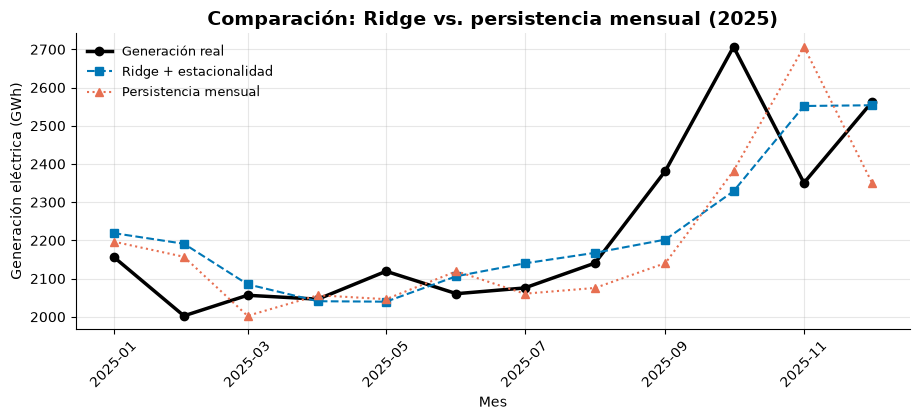

In [ ]:
# Código seleccionado del análisis original; ver interpretación en Markdown.
plt.figure(figsize=(9.3, 4.3))

plt.plot(
    y_test_3lags.index,
    y_test_3lags,
    label="Generación real",
    color="black",
    marker="o",
    linewidth=2.5
)

plt.plot(
    y_test_3lags.index,
    pred_ridge_ciclico,
    label="Ridge + estacionalidad",
    color="#0077b6",
    marker="s",
    linestyle="--"
)

plt.plot(
    y_test_3lags.index,
    pred_persistencia,
    label="Persistencia mensual",
    color="#e76f51",
    marker="^",
    linestyle=":"
)

plt.title(
    "Comparación: Ridge vs. persistencia mensual (2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Mes")
plt.ylabel("Generación eléctrica (GWh)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show();

### Resultados: Ridge frente al modelo de persistencia

Se comparó Ridge con estacionalidad frente a una
estrategia básica que utiliza la generación del
mes anterior como predicción del mes siguiente.
Los resultados obtenidos sobre 2025 fueron:
**Ridge con estacionalidad**

- MAE: 105,77 GWh
- RMSE: 149,82 GWh
- R²: 0,53

**Persistencia mensual**

- MAE: 133,69 GWh
- RMSE: 177,28 GWh
- R²: 0,34

Ridge consiguió reducir el error absoluto medio
aproximadamente un 20,88 % respecto del modelo
de persistencia.
El resultado demuestra que Ridge aportó una
mejora predictiva sobre esta estrategia sencilla
durante el período evaluado.
El gráfico también permite observar que la
persistencia reacciona con retraso a los cambios
bruscos de generación.
No obstante, Ridge mantiene errores relevantes
en determinados meses, especialmente cuando
la generación experimenta variaciones importantes.

### Conclusión

Ridge con estacionalidad se selecciona como el
mejor candidato entre los modelos evaluados para
pronósticos mensuales de un paso adelante.
Esta conclusión corresponde al protocolo de
evaluación utilizado y no demuestra todavía
su capacidad para realizar predicciones
de varios años hacia el futuro.

In [ ]:
# Crear una copia de los datos limpios
df_fuentes = df_original.copy()

# Normalizar nombres de las fuentes
df_fuentes["FUENTE DE ENERGÍA"] = (
    df_fuentes["FUENTE DE ENERGÍA"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Excluir Demanda MEM si estuviera presente
df_fuentes = df_fuentes[
    ~df_fuentes["FUENTE DE ENERGÍA"].str.contains(
        "DEMANDA MEM",
        case=False,
        na=False
    )
].copy()

# Agrupar información por fuente energética
resumen_fuentes = (
    df_fuentes
    .groupby("FUENTE DE ENERGÍA")
    .agg(
        Registros=("MES", "size"),
        Primer_mes=("MES", "min"),
        Ultimo_mes=("MES", "max"),
        Generacion_total_GWh=(
            "ENERGÍA GENERADA [GWh]",
            "sum"
        )
    )
    .reset_index()
)

# Ordenar por generación total
resumen_fuentes = resumen_fuentes.sort_values(
    "Generacion_total_GWh",
    ascending=False
)

display(resumen_fuentes.round(2))

,FUENTE DE ENERGÍA,Registros,Primer_mes,Ultimo_mes,Generacion_total_GWh
3,EOLICO,5953,2011-01-01,2026-08-01,"107.208,65"
5,SOLAR,4941,2011-01-01,2026-08-01,"23.569,79"
4,HIDRO <=50MW,7241,2011-01-01,2026-08-01,"21.850,25"
2,BIOMASA,1831,2011-01-01,2026-08-01,"6.810,48"
1,BIOGAS,2667,2012-05-01,2026-08-01,"3.766,34"
0,BIODIESEL,235,2011-01-01,2012-12-01,"2.380,61"


### Análisis de cobertura por fuente energética
Se identificaron seis fuentes de generación
renovable en el conjunto de datos:

- Eólica
- Solar
- Hidráulica de hasta 50 MW
- Biomasa
- Biogás
- Biodiésel

La generación eólica presenta el mayor volumen
acumulado durante el período analizado, con
107.208,65 GWh.
La generación solar y la hidráulica de hasta
50 MW ocupan las siguientes posiciones.
Se identificó una diferencia importante en
la cobertura temporal de biodiésel, cuya última
observación corresponde a diciembre de 2012.
Por esta razón, la ausencia de registros
posteriores no será interpretada automáticamente
como generación igual a cero.
Para las proyecciones futuras se priorizarán
las fuentes con registros recientes y cobertura
temporal suficiente.
Las comparaciones de participación energética
se realizarán utilizando períodos equivalentes.

In [ ]:
# Agrupar generación por mes y fuente energética

generacion_agrupada = (
    df_fuentes
    .groupby(["MES", "FUENTE DE ENERGÍA"])[
        "ENERGÍA GENERADA [GWh]"
    ]
    .sum(min_count=1)
    .unstack("FUENTE DE ENERGÍA")
)

# Crear calendario mensual completo
calendario = pd.date_range(
    start=df_fuentes["MES"].min(),
    end=df_fuentes["MES"].max(),
    freq="MS"
)

# Conservar meses sin registros como NaN
df_mensual_fuentes = (
    generacion_agrupada
    .reindex(calendario)
    .sort_index()
)

df_mensual_fuentes.index.name = "MES"

# Mostrar primeras observaciones
display(df_mensual_fuentes.head())

# Revisar cobertura mensual
cobertura_fuentes = pd.DataFrame({
    "Fuente": df_mensual_fuentes.columns,
    "Meses_con_registros": (
        df_mensual_fuentes.notna().sum().values
    ),
    "Meses_sin_registros": (
        df_mensual_fuentes.isna().sum().values
    )
})

display(cobertura_fuentes)

FUENTE DE ENERGÍA,BIODIESEL,BIOGAS,BIOMASA,EOLICO,HIDRO <=50MW,SOLAR
MES,,,,,,
2011-01-01,"0,00",NaN,"6,95","0,10","114,20","0,00"
2011-02-01,"0,00",NaN,"6,00","0,62","123,55","0,00"
2011-03-01,"0,00",NaN,"6,55","0,73","141,90","0,07"
2011-04-01,"0,00",NaN,"6,06","0,70","127,94","0,18"
2011-05-01,"5,47",NaN,"7,54","0,85","87,25","0,16"


,Fuente,Meses_con_registros,Meses_sin_registros
0,BIODIESEL,24,164
1,BIOGAS,172,16
2,BIOMASA,188,0
3,EOLICO,188,0
4,HIDRO <=50MW,188,0
5,SOLAR,188,0


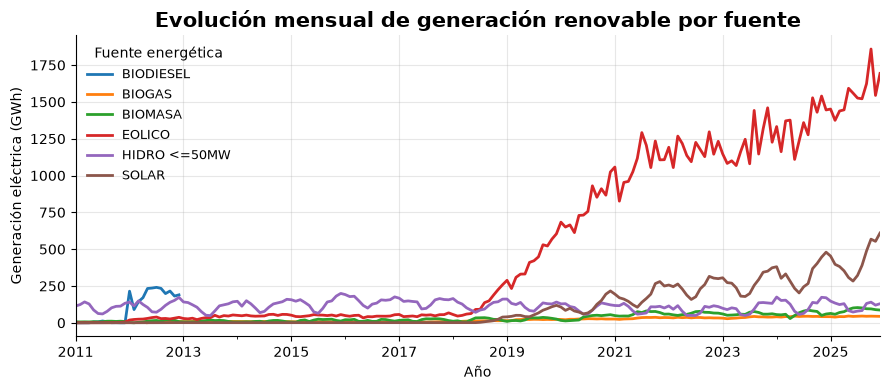

In [ ]:
# Seleccionar período histórico completo
datos_grafico = df_mensual_fuentes.loc[
    "2011-01-01":"2025-12-01"
]

# Crear gráfico
ax = datos_grafico.plot(
    figsize=(9, 4),
    linewidth=2
)

ax.set_title(
    "Evolución mensual de generación renovable por fuente",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Año")
ax.set_ylabel("Generación eléctrica (GWh)")

ax.legend(
    title="Fuente energética",
    loc="upper left"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show();

### Interpretación de la evolución por fuente energética

El análisis de la generación renovable mensual
entre 2011 y 2025 permite identificar diferencias
importantes entre las fuentes energéticas.
La energía eólica presenta el crecimiento más
pronunciado, especialmente a partir de 2018.
Durante 2025 alcanza valores mensuales superiores
a 1.800 GWh, posicionándose como la principal
fuente de generación renovable del conjunto analizado.
La energía solar también muestra una expansión
considerable, principalmente desde 2020, con
incrementos importantes durante los últimos años.
La generación hidráulica de hasta 50 MW presenta
oscilaciones recurrentes, mientras que biomasa
y biogás mantienen niveles de generación menores.
Por otra parte, biodiésel solamente dispone de
registros entre enero de 2011 y diciembre de 2012.
Esta discontinuidad impide construir pronósticos
futuros suficientemente fundamentados utilizando
exclusivamente su serie histórica.

### Conclusión

Las distintas fuentes renovables presentan
comportamientos temporales heterogéneos.
Por lo tanto, el análisis predictivo deberá
considerar las características particulares
de cada serie.
El crecimiento histórico no garantiza que
las tendencias continúen hasta 2030.
Será necesario evaluar los pronósticos y
representar su incertidumbre.

In [ ]:
# Seleccionar datos de 2025
fuentes_2025 = df_mensual_fuentes.loc["2025"].copy()

# Seleccionar las cinco fuentes con cobertura reciente
fuentes_activas = [
    "EOLICO",
    "SOLAR",
    "HIDRO <=50MW",
    "BIOMASA",
    "BIOGAS"
]

# Verificar que existan 12 meses y datos de todas las fuentes
assert len(fuentes_2025) == 12
assert fuentes_2025[fuentes_activas].notna().all().all()

# Calcular generación anual
generacion_anual = (
    fuentes_2025[fuentes_activas]
    .sum()
    .sort_values(ascending=False)
)

# Calcular participación
participacion = (
    generacion_anual
    / generacion_anual.sum()
    * 100
)

# Crear tabla
tabla_participacion = pd.DataFrame({
    "Generacion_GWh": generacion_anual,
    "Participacion_%": participacion
})

display(tabla_participacion.round(2))

,Generacion_GWh,Participacion_%
FUENTE DE ENERGÍA,,
EOLICO,"18.628,08","69,87"
SOLAR,"5.105,85","19,15"
HIDRO <=50MW,"1.374,09","5,15"
BIOMASA,"1.029,58","3,86"
BIOGAS,"521,77","1,96"


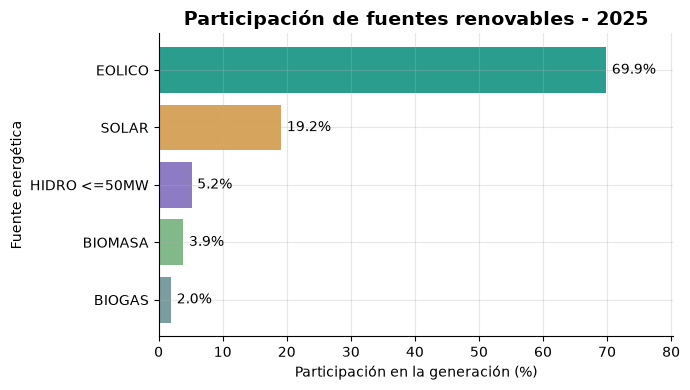

In [ ]:
# Gráfico de participación por fuente

datos = tabla_participacion.sort_values(
    "Participacion_%"
)

plt.figure(figsize=(7, 4))

barras = plt.barh(
    datos.index,
    datos["Participacion_%"],
    color=["#7A9E9F", "#83B88B", "#8D7CC3",
           "#D6A45D", "#2A9D8F"]
)

plt.bar_label(
    barras,
    fmt="%.1f%%",
    padding=4
)

plt.title(
    "Participación de fuentes renovables - 2025",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Participación en la generación (%)")
plt.ylabel("Fuente energética")

plt.xlim(
    0,
    datos["Participacion_%"].max() * 1.15
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show();

### Interpretación de la participación energética en 2025

Durante 2025, las cinco fuentes renovables
analizadas registraron una generación conjunta
aproximada de 26.659,37 GWh.
La energía eólica presentó la mayor participación,
con 18.628,08 GWh, equivalentes al 69,87 %.
La energía solar ocupó el segundo lugar, con
5.105,85 GWh y una participación del 19,15 %.
En conjunto, ambas fuentes representaron
aproximadamente el 89 % de la generación
incluida en el análisis.
Las demás participaciones fueron:

- Hidráulica hasta 50 MW: 5,15 %.
- Biomasa: 3,86 %.
- Biogás: 1,96 %.

Estos resultados muestran una fuerte concentración
de la generación renovable registrada en las
fuentes eólica y solar.
El año 2025 se utilizará como referencia histórica
para comparar la composición de las proyecciones
futuras.
Los porcentajes corresponden exclusivamente
a las cinco fuentes incluidas y no representan
la totalidad de la matriz eléctrica argentina.

# Modelos de pronóstico por fuente energética

## Estrategia de evaluación temporal

### Objetivo

Desarrollar y evaluar modelos capaces de
pronosticar la generación mensual de cada
fuente energética durante varios meses futuros.

### Diferencia respecto del modelo anterior

Los modelos anteriores utilizaron rezagos
mensuales reales para predecir un mes adelante.
Para proyectar hasta 2030 no estarán disponibles
los valores reales de todos los meses futuros.
Por esta razón, se evaluarán modelos que puedan
generar pronósticos utilizando información
disponible al momento de realizar la predicción.

### Estrategia
Se utilizarán períodos históricos completos:

- Entrenamiento inicial: hasta diciembre de 2023.
- Validación: enero a diciembre de 2024.
- Evaluación posterior: enero a diciembre de 2025.

La validación permitirá comparar configuraciones
sin utilizar información del período posterior.
Se compararán enfoques sencillos de referencia
contra modelos de tendencia y estacionalidad.

### Limitaciones

Las predicciones de largo plazo estarán sujetas
a incertidumbre debido a posibles cambios
tecnológicos, económicos, regulatorios
y de capacidad instalada.
Las proyecciones hasta 2030 tendrán carácter
exploratorio y no se presentarán como
valores garantizados.

In [ ]:
# Preparar datos para pronósticos por fuente

fuentes_modelar = [
    "EOLICO",
    "SOLAR",
    "HIDRO <=50MW",
    "BIOMASA",
    "BIOGAS"
]

# Seleccionar las cinco series
df_pronosticos = df_mensual_fuentes[
    fuentes_modelar
].copy()

# Utilizar un período con cobertura completa
df_pronosticos = df_pronosticos.loc[
    "2013-01-01":"2025-12-01"
]

# Verificar fechas faltantes
resumen_modelado = pd.DataFrame({
    "Fuente": df_pronosticos.columns,
    "Meses_disponibles": df_pronosticos.notna().sum().values,
    "Meses_faltantes": df_pronosticos.isna().sum().values,
    "Generacion_promedio_GWh": df_pronosticos.mean().values
})

display(resumen_modelado.round(2))

,Fuente,Meses_disponibles,Meses_faltantes,Generacion_promedio_GWh
0,EOLICO,156,0,"609,01"
1,SOLAR,156,0,"126,66"
2,HIDRO <=50MW,156,0,"117,48"
3,BIOMASA,156,0,"37,67"
4,BIOGAS,156,0,"21,71"


In [ ]:
# Generación anual por fuente energética

generacion_anual_fuentes = (
    df_pronosticos
    .groupby(df_pronosticos.index.year)
    .sum()
)

# Variación porcentual anual
crecimiento_anual = (
    generacion_anual_fuentes
    .pct_change(fill_method=None)
    * 100
)

# Mostrar los últimos años completos
display(
    generacion_anual_fuentes.loc[2020:2025].round(2)
)

display(
    crecimiento_anual.loc[2020:2025].round(2)
)

FUENTE DE ENERGÍA,EOLICO,SOLAR,HIDRO <=50MW,BIOMASA,BIOGAS
MES,,,,,
2020,"9.410,64","1.344,35","1.256,91","420,96","304,10"
2021,"12.937,55","2.195,56","1.175,43","750,19","377,97"
2022,"14.164,46","2.928,29","1.060,49","769,14","417,85"
2023,"14.475,43","3.259,46","1.183,36","732,08","435,61"
2024,"16.164,51","3.941,32","1.511,63","747,39","511,78"
2025,"18.628,08","5.105,85","1.374,09","1.029,58","521,77"


FUENTE DE ENERGÍA,EOLICO,SOLAR,HIDRO <=50MW,BIOMASA,BIOGAS
MES,,,,,
2020,"88,37","68,11","-14,04","40,71","19,01"
2021,"37,48","63,32","-6,48","78,21","24,29"
2022,"9,48","33,37","-9,78","2,53","10,55"
2023,"2,20","11,31","11,59","-4,82","4,25"
2024,"11,67","20,92","27,74","2,09","17,49"
2025,"15,24","29,55","-9,10","37,76","1,95"


## Backtest histórico de los escenarios 2026–2030
Probamos en años anteriores el mismo método de tasas constantes que utilizamos para explorar 2030. Comparamos generación total y acierto de la fuente líder; el backtest no garantiza el futuro.


In [ ]:
# Backtest a cuatro años: 2017–2021 como orígenes históricos.
# Los supuestos en cada origen usan solo los cuatro cambios anuales ya conocidos.
anual_backtest = df_pronosticos.groupby(df_pronosticos.index.year).sum(min_count=12)
assert anual_backtest.notna().all().all()

def tasas_historicas(origen):
    cambios = anual_backtest.pct_change(fill_method=None).loc[origen-3:origen]
    assert len(cambios)==4 and cambios.notna().all().all()
    return {'Conservador':cambios.quantile(.25),
            'Intermedio':cambios.median(),
            'Alto':cambios.quantile(.75)}

filas_bt=[]
detalle_bt=[]
for origen in range(2017,2022):
    tasas=tasas_historicas(origen)
    for horizonte in range(1,5):
        real=anual_backtest.loc[origen+horizonte,fuentes_modelar]
        for escenario in ['Sin crecimiento','Conservador','Intermedio','Alto']:
            tasa=pd.Series(0.,index=fuentes_modelar) if escenario=='Sin crecimiento' else tasas[escenario]
            pred=(anual_backtest.loc[origen,fuentes_modelar]*(1+tasa).pow(horizonte)).clip(lower=0)
            filas_bt.append({'Origen':origen,'Año':origen+horizonte,'Horizonte':horizonte,
                'Escenario':escenario,'Real_GWh':real.sum(),'Estimado_GWh':pred.sum(),
                'Lider_real':real.idxmax(),'Lider_estimado':pred.idxmax(),
                'Acierta_lider':int(real.idxmax()==pred.idxmax())})
            for fuente in fuentes_modelar:
                detalle_bt.append({'Origen':origen,'Año':origen+horizonte,
                    'Horizonte':horizonte,'Escenario':escenario,'Fuente':fuente,
                    'Real_GWh':real[fuente],'Estimado_GWh':pred[fuente]})

tabla_backtest=pd.DataFrame(filas_bt)
tabla_backtest['Error_total_pct']=100*(tabla_backtest['Estimado_GWh']-
    tabla_backtest['Real_GWh']).abs()/tabla_backtest['Real_GWh']
resumen_backtest=tabla_backtest.groupby(['Escenario','Horizonte']).agg(
    Error_medio_pct=('Error_total_pct','mean'),
    Acierto_lider_pct=('Acierta_lider','mean'),
    Origenes=('Origen','nunique'))
resumen_backtest['Acierto_lider_pct']*=100
display(resumen_backtest.round(2))

Error_medio_pct  Acierto_lider_pct  Origenes
Escenario       Horizonte                                              
Alto            1                    77,70             100,00         5
                2                   371,46              40,00         5
                3                 1.713,44              20,00         5
                4                 8.732,92              20,00         5
Conservador     1                    35,66             100,00         5
                2                    79,98              80,00         5
                3                   128,00              80,00         5
                4                   188,07              80,00         5
Intermedio      1                    46,82             100,00         5
                2                   164,62              80,00         5
                3                   471,57              20,00         5
                4                 1.369,26              20,00         5
Sin crecimiento 1                    30,79              80,00         5
                2                    48,50              60,00         5
                3                    56,01              60,00         5
                4                    61,52              60,00         5

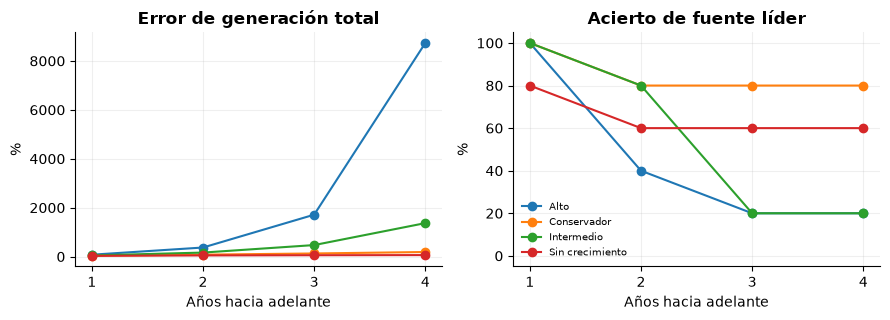

,Origen,Año,Lider_real,Lider_estimado,Error_total_pct
14,2017,2021,EOLICO,HIDRO <=50MW,"78,05"
30,2018,2022,EOLICO,EOLICO,"79,51"
46,2019,2023,EOLICO,SOLAR,"1.020,40"
62,2020,2024,EOLICO,SOLAR,"2.416,65"
78,2021,2025,EOLICO,SOLAR,"3.251,69"


In [ ]:
# Diagnóstico visual del backtest según horizonte de proyección.
fig, axes=plt.subplots(1,2,figsize=(9,3.3))
for nombre,grupo in resumen_backtest.reset_index().groupby('Escenario'):
    axes[0].plot(grupo['Horizonte'],grupo['Error_medio_pct'],marker='o',label=nombre)
    axes[1].plot(grupo['Horizonte'],grupo['Acierto_lider_pct'],marker='o',label=nombre)
axes[0].set(title='Error de generación total',ylabel='%')
axes[1].set(title='Acierto de fuente líder',ylabel='%')
for ax in axes:
    ax.set_xlabel('Años hacia adelante');ax.set_xticks([1,2,3,4]);ax.grid(alpha=.2)
axes[1].set_ylim(-5,105);axes[1].legend(frameon=False,fontsize=7)
plt.tight_layout();plt.show()
display(tabla_backtest.query('Escenario == "Intermedio" and Horizonte == 4')[
    ['Origen','Año','Lider_real','Lider_estimado','Error_total_pct']].round(2))

### Interpretación del backtest a 4 años

El escenario intermedio acertó la fuente líder en **1 de 5 evaluaciones** (20 %).
Además, los errores de generación aumentaron considerablemente en los períodos más recientes, superando el 3.000 %.

**Conclusión:** el modelo de escenarios presenta poca confiabilidad a cuatro años. Por lo tanto, las estimaciones hasta 2030 deben interpretarse como simulaciones exploratorias y no como pronósticos precisos.

### Interpretación del backtest (2026–2030)

El backtest muestra que **los errores de generación aumentan al proyectar más años**, especialmente en el escenario alto.
El escenario conservador presenta errores menores y mayor capacidad para identificar la fuente líder.

**Conclusión:** las proyecciones hasta 2030 son escenarios exploratorios, no predicciones garantizadas. Los resultados muestran la importancia de considerar la incertidumbre a largo plazo.

In [ ]:
# Comparar enero-agosto de 2025 y 2026

fuentes_2025_8m = df_mensual_fuentes.loc[
    "2025-01":"2025-08",
    fuentes_modelar
].sum()

fuentes_2026_8m = df_mensual_fuentes.loc[
    "2026-01":"2026-08",
    fuentes_modelar
].sum()

# Calcular crecimiento interanual
variacion_2026 = (
    (fuentes_2026_8m / fuentes_2025_8m) - 1
) * 100

# Crear tabla comparativa
tabla_2026 = pd.DataFrame({
    "Generacion_2025_8m": fuentes_2025_8m,
    "Generacion_2026_8m": fuentes_2026_8m,
    "Variacion_%": variacion_2026
})

display(tabla_2026.round(2))

,Generacion_2025_8m,Generacion_2026_8m,Variacion_%
FUENTE DE ENERGÍA,,,
EOLICO,"11.908,96","11.838,30","-0,59"
SOLAR,"2.887,73","3.801,21","31,63"
HIDRO <=50MW,"853,19","814,44","-4,54"
BIOMASA,"663,54","708,49","6,78"
BIOGAS,"344,42","343,42","-0,29"


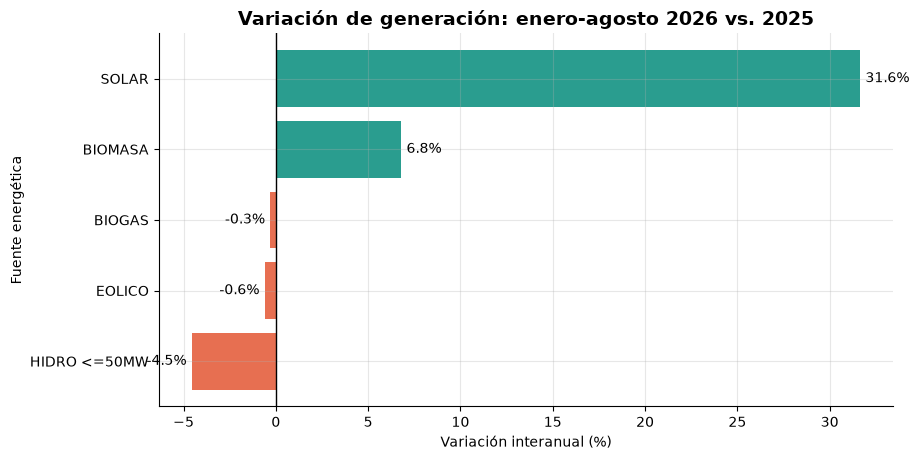

In [ ]:
# Gráfico de variación interanual 2026

datos = tabla_2026.sort_values("Variacion_%")

colores = [
    "#2A9D8F" if valor >= 0 else "#E76F51"
    for valor in datos["Variacion_%"]
]

plt.figure(figsize=(9.3, 4.7))

barras = plt.barh(
    datos.index,
    datos["Variacion_%"],
    color=colores
)

plt.axvline(0, color="black", linewidth=1)

plt.bar_label(
    barras,
    fmt="%.1f%%",
    padding=4
)

plt.title(
    "Variación de generación: enero-agosto 2026 vs. 2025",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Variación interanual (%)")
plt.ylabel("Fuente energética")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show();

### Interpretación de la evolución interanual de 2026

Se comparó la generación acumulada entre enero
y agosto de 2025 y el mismo período de 2026.
La energía solar presentó el mayor crecimiento
interanual, con un incremento del 31,63 %.
La biomasa aumentó un 6,78 %, mientras que
la generación eólica mostró una leve disminución
del 0,59 %.
La generación hidráulica de hasta 50 MW
disminuyó un 4,54 %, y biogás registró
una variación de -0,29 %.
Estos resultados muestran diferencias
importantes entre las fuentes energéticas.
La expansión reciente de la generación solar
constituye un hallazgo relevante para el
análisis de escenarios futuros.
Sin embargo, los resultados corresponden
únicamente a los primeros ocho meses de 2026.
No deben interpretarse como variaciones
definitivas del año completo.

### Conclusión

Los escenarios de evolución hasta 2030 deberán
considerar las diferencias entre fuentes y
las tendencias recientes.
Las tasas históricas se utilizarán como
referencias para explorar posibles trayectorias,
no como garantías de crecimiento futuro.

In [ ]:
# Estimación provisional del cierre de 2026

# Generación real de enero a agosto de 2026
real_2026 = df_mensual_fuentes.loc[
    "2026-01":"2026-08",
    fuentes_modelar
].sum()

# Generación del mismo período de 2025
real_2025_8m = df_mensual_fuentes.loc[
    "2025-01":"2025-08",
    fuentes_modelar
].sum()

# Generación de septiembre a diciembre de 2025
ultimos_4_2025 = df_mensual_fuentes.loc[
    "2025-09":"2025-12",
    fuentes_modelar
].sum()

# Factor de variación interanual
factor_crecimiento = real_2026 / real_2025_8m

# Estimación de septiembre a diciembre de 2026
estimacion_4m = (
    ultimos_4_2025 * factor_crecimiento
)

# Estimación anual completa
estimacion_2026 = real_2026 + estimacion_4m

# Tabla de resultados
tabla_cierre_2026 = pd.DataFrame({
    "Real_ene_ago_2026": real_2026,
    "Estimado_sep_dic_2026": estimacion_4m,
    "Total_estimado_2026": estimacion_2026
})

display(tabla_cierre_2026.round(2))

,Real_ene_ago_2026,Estimado_sep_dic_2026,Total_estimado_2026
FUENTE DE ENERGÍA,,,
EOLICO,"11.838,30","6.679,25","18.517,55"
SOLAR,"3.801,21","2.919,78","6.720,98"
HIDRO <=50MW,"814,44","497,25","1.311,69"
BIOMASA,"708,49","390,85","1.099,34"
BIOGAS,"343,42","176,83","520,26"


In [ ]:
# Tasas para escenarios exploratorios

tasas_recientes = crecimiento_anual.loc[
    2022:2025,
    fuentes_modelar
]

tasas_escenarios = pd.DataFrame({
    "Conservador": tasas_recientes.quantile(0.25),
    "Intermedio": tasas_recientes.median(),
    "Alto": tasas_recientes.quantile(0.75)
})

display(tasas_escenarios.round(2))

,Conservador,Intermedio,Alto
FUENTE DE ENERGÍA,,,
EOLICO,"7,66","10,58","12,56"
SOLAR,"18,52","25,23","30,50"
HIDRO <=50MW,"-9,27","1,24","15,62"
BIOMASA,"0,36","2,31","11,33"
BIOGAS,"3,68","7,40","12,28"


In [ ]:
# Construir escenarios anuales 2026-2030

resultados_escenarios = []

for fuente in fuentes_modelar:

    # Generación base estimada para 2026
    base_2026 = estimacion_2026[fuente]

    for escenario in [
        "Conservador",
        "Intermedio",
        "Alto"
    ]:

        # Tasa anual de crecimiento
        tasa = tasas_escenarios.loc[
            fuente, escenario
        ] / 100

        for anio in range(2026, 2031):

            # Años transcurridos desde 2026
            n = anio - 2026

            # Crecimiento compuesto
            generacion = base_2026 * (1 + tasa) ** n

            resultados_escenarios.append({
                "Año": anio,
                "Fuente": fuente,
                "Escenario": escenario,
                "Generacion_GWh": generacion
            })

# Crear DataFrame
df_escenarios = pd.DataFrame(
    resultados_escenarios
)

# Verificar resultados
display(df_escenarios.head(10).round(2))

,Año,Fuente,Escenario,Generacion_GWh
0,2026,EOLICO,Conservador,"18.517,55"
1,2027,EOLICO,Conservador,"19.936,24"
2,2028,EOLICO,Conservador,"21.463,62"
3,2029,EOLICO,Conservador,"23.108,02"
4,2030,EOLICO,Conservador,"24.878,40"
5,2026,EOLICO,Intermedio,"18.517,55"
6,2027,EOLICO,Intermedio,"20.475,96"
7,2028,EOLICO,Intermedio,"22.641,48"
8,2029,EOLICO,Intermedio,"25.036,04"
9,2030,EOLICO,Intermedio,"27.683,84"


In [ ]:
# Seleccionar escenario intermedio de 2030

escenario_2030 = df_escenarios[
    (df_escenarios["Año"] == 2030) &
    (df_escenarios["Escenario"] == "Intermedio")
].copy()

# Calcular participación porcentual
total_2030 = escenario_2030["Generacion_GWh"].sum()

escenario_2030["Participacion_%"] = (
    escenario_2030["Generacion_GWh"]
    / total_2030
    * 100
)

# Ordenar por generación proyectada
escenario_2030 = escenario_2030.sort_values(
    "Generacion_GWh",
    ascending=False
)

display(
    escenario_2030[
        ["Fuente", "Generacion_GWh", "Participacion_%"]
    ].round(2)
)

,Fuente,Generacion_GWh,Participacion_%
9,EOLICO,"27.683,84","58,29"
24,SOLAR,"16.531,32","34,81"
39,HIDRO <=50MW,"1.378,16","2,90"
54,BIOMASA,"1.204,46","2,54"
69,BIOGAS,"692,21","1,46"


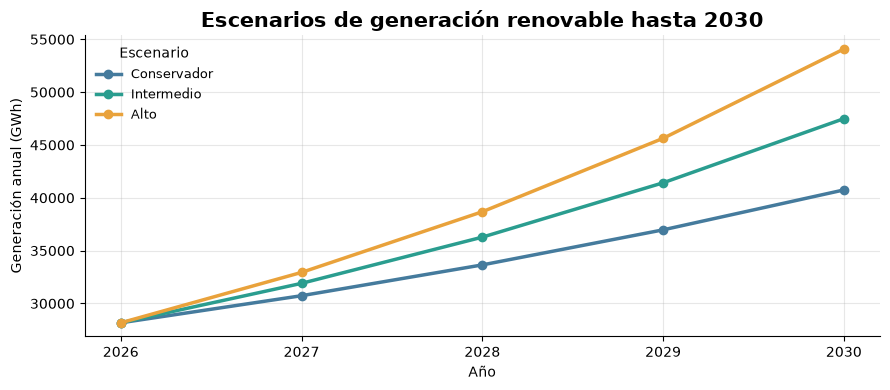

In [ ]:
# Generación total por año y escenario

totales_escenarios = (
    df_escenarios
    .groupby(["Año", "Escenario"])["Generacion_GWh"]
    .sum()
    .unstack("Escenario")
)

# Crear gráfico
plt.figure(figsize=(9, 4))

colores = {
    "Conservador": "#457B9D",
    "Intermedio": "#2A9D8F",
    "Alto": "#E9A23B"
}

for escenario in [
    "Conservador",
    "Intermedio",
    "Alto"
]:

    plt.plot(
        totales_escenarios.index,
        totales_escenarios[escenario],
        marker="o",
        linewidth=2.5,
        color=colores[escenario],
        label=escenario
    )

plt.title(
    "Escenarios de generación renovable hasta 2030",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Año")
plt.ylabel("Generación anual (GWh)")

plt.xticks(range(2026, 2031))
plt.legend(title="Escenario")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show();

### Interpretación de los escenarios hasta 2030

Los tres escenarios muestran un crecimiento de la generación renovable entre 2026 y 2030.
Para 2030, el escenario conservador estima aproximadamente **40.700 GWh**, el intermedio **47.490 GWh** y el alto **54.000 GWh**.

**Conclusión:** la generación podría aumentar bajo los supuestos planteados. Sin embargo, debido a los elevados errores del backtest, estos resultados son simulaciones exploratorias y no pronósticos garantizados.

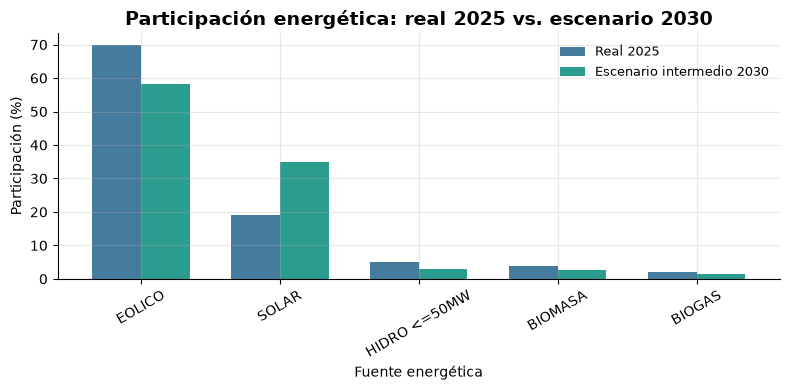

In [ ]:
# Comparar participación real 2025 vs escenario 2030

comparacion_participacion = pd.DataFrame({
    "Real_2025": tabla_participacion["Participacion_%"],
    "Escenario_2030": escenario_2030.set_index(
        "Fuente"
    )["Participacion_%"]
})

# Ordenar según participación real de 2025
comparacion_participacion = (
    comparacion_participacion
    .sort_values("Real_2025", ascending=False)
)

# Crear gráfico
ax = comparacion_participacion.plot(
    kind="bar",
    figsize=(8, 4),
    color=["#457B9D", "#2A9D8F"],
    width=0.7
)

ax.set_title(
    "Participación energética: real 2025 vs. escenario 2030",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Fuente energética")
ax.set_ylabel("Participación (%)")

ax.legend([
    "Real 2025",
    "Escenario intermedio 2030"
])

ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show();

### Conclusión general del análisis de escenarios

El análisis histórico y predictivo permitió
estudiar la evolución de cinco fuentes de
generación renovable en Argentina.
Durante 2025, la energía eólica representó
el 69,87 % de la generación analizada,
seguida por la solar con el 19,15 %.
Se construyeron tres escenarios exploratorios
hasta 2030 utilizando tasas de crecimiento
diferenciadas por fuente energética.
En el escenario intermedio, la generación
eólica mantendría la mayor participación,
con un 58,29 %.
La participación solar aumentaría hasta
aproximadamente el 34,81 %.
Estos resultados sugieren que, bajo los
supuestos definidos, la composición energética
podría experimentar cambios importantes.
Sin embargo, las evaluaciones de pronósticos
a 48 meses evidenciaron errores elevados
en determinados períodos.
Por lo tanto, los escenarios de 2030 no deben
interpretarse como pronósticos garantizados.


# Conclusión general del proyecto
## Análisis y predicción de energías renovables en Argentina

El presente proyecto permitió analizar la evolución de la generación de energías renovables en Argentina durante el período **2011–agosto de 2026**, aplicando herramientas de Ciencia de Datos como Python, Pandas, NumPy, Matplotlib y Scikit-learn.

El trabajo se desarrolló en distintas etapas: limpieza y preparación de datos, análisis exploratorio (EDA), visualización, construcción de modelos de Machine Learning y elaboración de escenarios energéticos hasta 2030.

### 1. Principales resultados del análisis exploratorio

El análisis permitió identificar diferencias importantes entre las fuentes de generación renovable.

- **Energía eólica:** fue la principal fuente de generación del conjunto analizado y presentó el mayor crecimiento absoluto entre 2011 y 2025.
- **Energía solar:** mostró una expansión significativa. Entre enero y agosto de 2026 registró un crecimiento interanual del 31,63 %, siendo la fuente con mayor aumento porcentual en ese período.
- **Biomasa y biogás:** presentaron una participación menor, pero contribuyen a la diversificación de las fuentes renovables.
- **Hidráulica de hasta 50 MW:** mostró variaciones en su generación, incluyendo una disminución del 4,54 % durante los primeros ocho meses de 2026.

También se identificaron diferencias geográficas en la generación, lo que permitió conocer las provincias con mayor participación y las fuentes predominantes en cada región.

### 2. Aplicación de Machine Learning

Se desarrollaron modelos de regresión para estimar la generación eléctrica renovable mensual a partir de datos históricos.

Se compararon tres enfoques:

- **Persistencia mensual:** utilizada como referencia para evaluar si los modelos predictivos aportaban una mejora.
- **Regresión lineal:** permitió establecer un primer modelo utilizando la generación de meses anteriores.
- **Ridge Regression con estacionalidad:** incorporó variables temporales y regularización para mejorar las estimaciones.

En la evaluación realizada sobre 2025, Ridge con estacionalidad obtuvo un **MAE de 105,77 GWh y un R² de 0,53**, superando al modelo de persistencia mensual.

Estos resultados mostraron que incorporar información histórica y estacional puede mejorar la predicción. Sin embargo, el análisis de residuos permitió identificar meses con errores importantes.

Por lo tanto, un buen resultado promedio no significa que el modelo pueda anticipar correctamente todos los cambios en la generación.

### 3. Escenarios de generación renovable hasta 2030

A partir de los registros históricos y una estimación provisional de cierre de 2026, se construyeron tres escenarios de evolución energética:

- **Conservador:** aproximadamente 40.700 GWh en 2030.
- **Intermedio:** aproximadamente 47.490 GWh en 2030.
- **Alto:** aproximadamente 54.000 GWh en 2030.

En el escenario intermedio, la energía eólica mantendría la mayor participación, mientras que la solar aumentaría su importancia dentro de las cinco fuentes analizadas.

Estos escenarios permiten explorar posibles cambios en la composición de la generación renovable bajo distintos supuestos de crecimiento.

### 4. Validación mediante backtest

Para evaluar la confiabilidad de las proyecciones a largo plazo, se realizó un backtest utilizando períodos históricos y horizontes de hasta cuatro años.

Los resultados mostraron que los errores de generación aumentaban considerablemente al extender el horizonte de proyección.

En particular, el escenario intermedio logró identificar correctamente la fuente líder en solamente **1 de 5 evaluaciones a cuatro años**.

Esto demuestra que utilizar tasas de crecimiento históricas constantes puede producir estimaciones poco precisas cuando las condiciones del sector cambian.

En consecuencia, los escenarios hasta 2030 deben interpretarse como **simulaciones exploratorias y no como pronósticos garantizados**.

### 5. Conclusión final y aprendizajes

El desarrollo de este proyecto permitió integrar conocimientos de programación, estadística, análisis exploratorio y Machine Learning para estudiar un problema relacionado con el sector energético argentino.

Uno de los principales aprendizajes fue comprender la importancia de preparar correctamente los datos, seleccionar variables adecuadas y comparar modelos utilizando métricas de evaluación.

También se comprobó que **un modelo más complejo no necesariamente produce mejores predicciones** y que analizar los errores es fundamental para interpretar los resultados.

El estudio muestra el crecimiento histórico de la generación renovable, especialmente de las fuentes eólica y solar, aunque no permite asegurar cómo evolucionará el sector en los próximos años.

**En conclusión, la Ciencia de Datos permite transformar registros históricos en información útil para comprender tendencias, comparar alternativas y construir escenarios, siempre reconociendo la incertidumbre y las limitaciones de los modelos utilizados.**

### 6. Próximas etapas del proyecto

Como continuación del trabajo, se propone desarrollar:

1. **Un dashboard en Power BI**, para visualizar la evolución histórica, la participación de cada fuente energética, las diferencias geográficas y los resultados del análisis.
2. **Una aplicación interactiva**, que permita consultar los datos, comparar escenarios hasta 2030 y explorar los resultados obtenidos con Machine Learning.

Estas herramientas permitirán presentar los hallazgos de manera más visual, accesible e interactiva, completando el proceso de análisis y comunicación de resultados del proyecto.

## Exportación de resultados para Power BI y Streamlit

### Objetivo

Generar archivos CSV con los datos históricos
y los escenarios energéticos desarrollados.

### Archivos

1. Generación mensual histórica por fuente.
2. Generación anual histórica por fuente.
3. Escenarios energéticos 2026–2030.

Los archivos permitirán construir indicadores,
gráficos y filtros interactivos en Power BI
y en la aplicación web.
Las proyecciones estarán identificadas como
escenarios simulados para diferenciarlas
de las observaciones históricas.

In [ ]:
# Código seleccionado del análisis original; ver interpretación en Markdown.
from pathlib import Path

# Crear carpeta de exportaciones
carpeta_exportacion = Path("exportaciones")
carpeta_exportacion.mkdir(exist_ok=True)

# Histórico mensual en formato largo
historico_mensual = (
    df_mensual_fuentes[fuentes_modelar]
    .reset_index()
    .melt(
        id_vars="MES",
        var_name="Fuente",
        value_name="Generacion_GWh"
    )
)

# Histórico anual en formato largo
historico_anual = (
    generacion_anual_fuentes
    .reset_index()
    .rename(columns={"MES": "Año"})
    .melt(
        id_vars="Año",
        var_name="Fuente",
        value_name="Generacion_GWh"
    )
)

# Guardar archivos
historico_mensual.to_csv(
    carpeta_exportacion / "historico_mensual_fuentes.csv",
    index=False,
    encoding="utf-8-sig"
)

historico_anual.to_csv(
    carpeta_exportacion / "historico_anual_fuentes.csv",
    index=False,
    encoding="utf-8-sig"
)

df_escenarios.to_csv(
    carpeta_exportacion / "escenarios_energia_2030.csv",
    index=False,
    encoding="utf-8-sig"
)

# Verificar exportaciones
archivos_exportados = pd.DataFrame({
    "Archivo": [
        "historico_mensual_fuentes.csv",
        "historico_anual_fuentes.csv",
        "escenarios_energia_2030.csv"
    ],
    "Estado": ["Generado"] * 3
})

display(archivos_exportados)
# Datos del backtest y métricas finales para Power BI y la app.
tabla_backtest.to_csv(carpeta_exportacion / "backtest_escenarios_48m.csv",
                       index=False,encoding="utf-8-sig")
pd.DataFrame(detalle_bt).to_csv(carpeta_exportacion / "backtest_fuentes_48m.csv",
                               index=False,encoding="utf-8-sig")
tabla_final_ml.to_csv(carpeta_exportacion / "comparacion_modelos_ml.csv",
                      index=False,encoding="utf-8-sig")
print("Exportaciones listas para Power BI y app.")


,Archivo,Estado
0,historico_mensual_fuentes.csv,Generado
1,historico_anual_fuentes.csv,Generado
2,escenarios_energia_2030.csv,Generado


Exportaciones listas para Power BI y app.
